# SP519 · Prédiction du flux d'électrons de 1 MeV en LEO (NOAA-15)

## Step 1 : préparation des données et analyse statistique
Le notebook suit, dans l'ordre, les 7 points du Step 1 de l'énoncé :

1. Récupérer les données NOAA-15 SEM-2 et les paramètres solaires pour 2020–2024
2. Nettoyer et synchroniser les données (valeurs manquantes, valeurs invalides, outliers, horodatage)
3. Choisir la région des ceintures de radiation (plage de L) et justifier ce choix
4. Moyenner tous les paramètres sur des intervalles de 12 h
5. Visualiser les séries temporelles (flux vs temps, L vs temps, paramètres solaires vs temps)
6. Statistiques descriptives, relations entre le flux et les paramètres solaires, outliers
7. Déterminer le seuil du 95ᵉ percentile du flux, qui définit les « événements »

(La cellule « 0 » ci-dessous contient seulement les imports et les paramètres.)

## 0. Imports et paramètres

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda x: f'{x:,.4g}')
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'lines.linewidth': 1.0, 'font.size': 9})

# Dossiers (relatifs au notebook)
PROJ = os.getcwd()
DATA = os.path.join(PROJ, 'data')
FIG = os.path.join(PROJ, 'figures')
os.makedirs(DATA, exist_ok=True)
os.makedirs(FIG, exist_ok=True)

# Paramètres de l'étude
START, END = pd.Timestamp('2020-01-01'), pd.Timestamp('2025-01-01')   # période [START, END[
STEP = '12h'            # résolution temporelle des prédictions
# La région de la ceinture (L_LO <= L < L_HI) est choisie automatiquement au point 3
P_EVENT = 95            # percentile définissant un "événement"

def savefig(fig, name):
    # Sauvegarde des figures pour le rapport
    fig.savefig(os.path.join(FIG, name), dpi=150, bbox_inches='tight')

print('Dossier du projet :', PROJ)

Dossier du projet : C:\Repertoire_de_travail\123Soleil\Prediction-of-1-MeV-electron-fluxes-in-LEO


## 1. Récupération des données (NOAA-15 SEM-2 + paramètres solaires, 2020–2024)

### 1.1 Téléchargement des fichiers bruts NOAA-15
Un fichier par jour sur le serveur NCEI (`poes_n15_AAAAMMJJ_proc.nc`, ~6,6 Mo, une mesure toutes les 2 s), soit
~1 800 fichiers et ~12 Go pour 2020–2024. Ils sont rangés dans `data/noaa15_raw/` (ignoré par Git).
Le téléchargement est **désactivé par défaut** (`TELECHARGER = False`) pour que le notebook puisse s'exécuter de haut
en bas sans retélécharger 12 Go : les tables résumées du point 1.2 sont déjà dans `data/`.

In [2]:
import calendar
from concurrent.futures import ThreadPoolExecutor
from typing import List

import requests

TELECHARGER = False                          # True pour (re)télécharger les fichiers bruts NOAA-15
RAW_DIR = os.path.join(DATA, 'noaa15_raw')   # fichiers bruts (ignorés par Git)
MAX_WORKERS = 4                              # au-delà, le serveur NCEI bloque des connexions

def download_nc_files(
    years: List[int],
    months: List[int],
    data_dir: str = RAW_DIR,
    max_workers: int = MAX_WORKERS,
) -> None:
    """Downloads NOAA-15 POES daily NetCDF files into data_dir.

    Files already present are skipped (the download can be resumed), and a file
    whose download fails is deleted (no half-written file is left behind).

    Args:
        years: List of years (e.g., [2020, 2021]).
        months: List of months as integers; downloads every day in each month.
        data_dir: Path to the local directory where files will be stored.
        max_workers: Maximum number of files to download concurrently.
    """
    if max_workers < 1:
        raise ValueError("max_workers must be at least 1")

    files_to_download = []
    for year in years:
        for month in months:
            if not 1 <= month <= 12:
                raise ValueError(f"Month must be between 1 and 12, got {month}")
            for day in range(1, calendar.monthrange(year, month)[1] + 1):
                date_str = f"{year:04d}{month:02d}{day:02d}"
                files_to_download.append(
                    (
                        year,
                        date_str,
                        f"poes_n15_{date_str}_proc.nc",
                    )
                )

    # 1. Create the destination directory (existing files are kept)
    os.makedirs(data_dir, exist_ok=True)

    base_url = (
        "https://www.ncei.noaa.gov/data/poes-metop-space-environment-monitor/"
        "access/l1b/v01r00/{year}/noaa15/poes_n15_{date_str}_proc.nc"
    )

    def download_file(file_info):
        year, date_str, filename = file_info
        file_url = base_url.format(year=year, date_str=date_str)
        destination_path = os.path.join(data_dir, filename)
        if os.path.exists(destination_path):
            return                                   # already downloaded
        tmp_path = destination_path + ".part"        # renamed only once complete

        print(f"Downloading: {file_url}")
        try:
            with requests.get(file_url, stream=True, timeout=30) as response:
                response.raise_for_status()

                with open(tmp_path, "wb") as f:
                    for chunk in response.iter_content(chunk_size=8192):
                        f.write(chunk)

            os.replace(tmp_path, destination_path)
            print(f"Successfully saved to {destination_path}")

        except requests.exceptions.RequestException as e:
            if os.path.exists(tmp_path):
                os.remove(tmp_path)
            print(f"Failed to download {file_url}: {e}")

    # 2. Download daily files concurrently to reduce time spent waiting on the server.
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        list(executor.map(download_file, files_to_download))


if TELECHARGER:
    download_nc_files(years=list(range(START.year, END.year)), months=list(range(1, 13)))
else:
    print('Téléchargement désactivé (TELECHARGER = False) : on utilise les tables déjà présentes dans data/.')

Téléchargement désactivé (TELECHARGER = False) : on utilise les tables déjà présentes dans data/.


### 1.2 Paramètres solaires et géomagnétiques (OMNI)
Base **OMNI2 horaire** (`OMNI2_H0_MRG1HR`) de la NASA (SPDF / CDAWeb) : mesures du vent solaire (sondes ACE, Wind…)
ramenées jusqu'à la Terre, et indices géomagnétiques, sur une même base de temps horaire UTC. Deux fichiers CDF par an
(janvier–juin, juillet–décembre), soit 10 fichiers d'environ 1,5 Mo, lus avec `cdflib`.

| Variable OMNI | Nom dans le notebook | Rôle physique |
|---|---|---|
| `V` | `V_kms` | vitesse du vent solaire : principal moteur de l'accélération des électrons relativistes |
| `BZ_GSM` | `Bz_nT` | Bz < 0 → reconnexion magnétique, injection de particules dans la magnétosphère |
| `F10_INDEX` | `F107_sfu` | flux radio solaire à 10,7 cm : niveau d'activité du cycle solaire |
| `N`, `Pressure` | `N_cm3`, `P_nPa` | densité et pression dynamique : compression de la magnétosphère, pertes d'électrons |
| `E` | `E_mVm` | champ électrique −V·Bz : couplage vent solaire / magnétosphère |
| `ABS_B` | `B_nT` | intensité du champ magnétique interplanétaire |
| `KP`, `DST`, `AE` | `Kp`, `Dst_nT`, `AE_nT` | activité géomagnétique : globale (Kp), orages (Dst), sous-orages (AE) |

V, Bz et F10.7 sont demandés par l'énoncé ; les autres sont ajoutés pour les raisons physiques ci-dessus.
Les valeurs manquantes sont codées dans les CDF par une valeur de remplissage (attribut `FILLVAL`, ex. 9999 pour V) :
on les remplace par NaN. `KP` est stocké ×10 (Kp = 3+ → 33) : on le divise par 10.
Le flux de protons > 10 MeV (`PR-FLX_10`) n'est pas gardé : il manque à ~97 % sur 2020–2024.

In [3]:
import cdflib

OMNI_DIR = os.path.join(DATA, 'omni')   # fichiers CDF bruts (ignorés par Git)
OMNI_URL = 'https://spdf.gsfc.nasa.gov/pub/data/omni/omni_cdaweb/hourly/{y}/omni2_h0_mrg1hr_{y}{m}01_v01.cdf'
OMNI_VARS = {'V': 'V_kms', 'BZ_GSM': 'Bz_nT', 'F10_INDEX': 'F107_sfu', 'N': 'N_cm3', 'Pressure': 'P_nPa',
             'E': 'E_mVm', 'ABS_B': 'B_nT', 'KP': 'Kp', 'DST': 'Dst_nT', 'AE': 'AE_nT'}
os.makedirs(OMNI_DIR, exist_ok=True)

morceaux = []
for y in range(START.year, END.year):
    for m in ('01', '07'):                                   # un fichier par semestre
        path = os.path.join(OMNI_DIR, f'omni2_h0_mrg1hr_{y}{m}01_v01.cdf')
        if not os.path.exists(path):                         # téléchargé une seule fois
            r = requests.get(OMNI_URL.format(y=y, m=m), timeout=60)
            r.raise_for_status()
            with open(path, 'wb') as f:
                f.write(r.content)
        cdf = cdflib.CDF(path)
        d = {'time': cdflib.cdfepoch.to_datetime(cdf.varget('Epoch'))}
        for var, nom in OMNI_VARS.items():
            x = cdf.varget(var).astype(float)
            fill = cdf.varattsget(var)['FILLVAL']
            x[np.isclose(x, fill) | (x >= fill)] = np.nan       # valeur de remplissage -> NaN
            d[nom] = x
        morceaux.append(pd.DataFrame(d))

omni_raw = pd.concat(morceaux).drop_duplicates('time').set_index('time').sort_index()
omni_raw = omni_raw.loc[START:END - pd.Timedelta('1h')]
omni_raw['Kp'] = omni_raw['Kp'] / 10                         # Kp*10 -> Kp
omni_raw.index = pd.DatetimeIndex(omni_raw.index).as_unit('ns')
omni_raw.to_parquet(os.path.join(DATA, 'omni_hourly_2020_2024.parquet'))
print('OMNI :', omni_raw.shape, '|', omni_raw.index.min(), '->', omni_raw.index.max())

OMNI : (43848, 10) | 2020-01-01 00:00:00 -> 2024-12-31 23:00:00


### 1.3 Tables utilisées dans la suite du notebook
La cellule ci-dessous lit les deux tables de `data/` ; tout le reste du notebook ne dépend que d'elles.

* `noaa15_p6_hourly_Lbins.parquet` : le flux `mep_pro_tel90_flux_p6` de NOAA-15, résumé **heure par heure et par
  tranche de L** (L de 1 à 8 par pas de 0,25, et `Lbin = 10` pour la calotte polaire L ≥ 10).
  Colonnes : `time` (début de l'heure, UTC), `Lbin`, `p6_sum` (somme des flux), `n` (nombre de mesures),
  `p6_max` (plus grande mesure de 2 s de la case, utile pour repérer les pics aberrants),
  `omni_p1_sum` / `omni_p1_n` (idem pour les protons 25 MeV, utiles au point 2).
  → Produite au **point 2** à partir des fichiers bruts (nettoyage puis résumé) : **en cours, autre membre du
  binôme**. En attendant, la version présente dans `data/` a été produite selon le même principe.
* `omni_hourly_2020_2024.parquet` : paramètres OMNI heure par heure (index `time`, UTC) : `V_kms`, `Bz_nT`,
  `F107_sfu`, `N_cm3`, `P_nPa`, `E_mVm`, `B_nT`, `Kp`, `Dst_nT`, `AE_nT`.
  → Produite par la cellule OMNI ci-dessus (1.2).

In [4]:
noaa = pd.read_parquet(os.path.join(DATA, 'noaa15_p6_hourly_Lbins.parquet'))
omni = pd.read_parquet(os.path.join(DATA, 'omni_hourly_2020_2024.parquet'))

L_POLAR = 10.0   # code de la tranche "calotte polaire" (L >= 10)

print('NOAA-15 :', noaa.shape, '|', noaa.time.min(), '->', noaa.time.max())
print('   tranches de L :', [float(l) for l in sorted(noaa.Lbin.unique())])
jours = noaa.time.dt.floor('D').unique()
print('   jours avec données :', len(jours), '/', (END - START).days)
print('OMNI    :', omni.shape, '|', omni.index.min(), '->', omni.index.max())
print('   % manquant :', omni.isna().mean().mul(100).round(2).to_dict())
noaa.head()

NOAA-15 : (1234141, 7) | 2020-01-01 00:00:00 -> 2024-12-31 22:00:00
   tranches de L : [1.0, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5, 2.75, 3.0, 3.25, 3.5, 3.75, 4.0, 4.25, 4.5, 4.75, 5.0, 5.25, 5.5, 5.75, 6.0, 6.25, 6.5, 6.75, 7.0, 7.25, 7.5, 7.75, 10.0]
   jours avec données : 1808 / 1827
OMNI    : (43848, 10) | 2020-01-01 00:00:00 -> 2024-12-31 23:00:00
   % manquant : {'V_kms': 1.47, 'Bz_nT': 0.68, 'F107_sfu': 0.05, 'N_cm3': 1.53, 'P_nPa': 1.53, 'E_mVm': 1.6, 'B_nT': 0.68, 'Kp': 0.0, 'Dst_nT': 0.0, 'AE_nT': 0.0}


,time,Lbin,p6_sum,n,p6_max,omni_p1_sum,omni_p1_n
0,2020-01-01,1,3.598e+05,233,"5,610","1,171",233
1,2020-01-01,1.25,6.118e+05,257,"8,415","1,214",257
2,2020-01-01,1.5,4.78e+04,143,"2,195",90.2,143
3,2020-01-01,1.75,"7,317",125,487.8,8.931,125
4,2020-01-01,2,"8,537",93,487.8,2.578,93


## 2. Nettoyage et synchronisation

Le nettoyage se fait à deux niveaux (code écrit par l'autre membre du binôme, intégré ici) :

* **2.1 – 2.2 : les mesures brutes** (une toutes les 2 s, un fichier par jour). Démonstration sur une journée de ce
  qu'il faut retirer d'un fichier brut. La réduction des ~1 800 fichiers bruts en table horaire par tranche de L
  (`noaa15_p6_hourly_Lbins.parquet`, point 1.3) a été faite une fois, hors notebook (~12 Go à télécharger).
* **2.3 : la table horaire** utilisée par toute la suite : heures sans mesure, pics aberrants, périodes où P6 ne
  mesure plus des électrons (protons solaires), et synchronisation avec OMNI.

Ce que fait le code de 2.1 sur les mesures brutes :
* **horodatage** (`as_dataframe`) : temps converti en dates UTC, triées, sans doublon ;
* **valeurs invalides / manquantes** (`clean_raw`) : flux négatifs (valeurs de remplissage −999) → NaN ; L invalide
  (−1 = valeur de remplissage, L ≈ 100 = ligne de champ ouverte) ; mesures prises pendant l'étalonnage en vol
  (`mep_IFC_on = 1`) retirées ; mesures sans flux ou sans L retirées ;
* **valeurs aberrantes** (`mask_outliers`) : dans chaque tranche de L de largeur 1, une mesure est aberrante si son
  log10(flux) sort de [Q1 − 3·IQR ; Q3 + 3·IQR]. Limite constatée : dans les zones presque vides (« slot »,
  calotte polaire), cette règle retire de vraies mesures de 2 à 4 coups. C'est pourquoi les pics aberrants sont
  traités autrement en 2.3 (seuil physique) ;
* **synchronisation** (`synchronize`) : met d'autres séries (OMNI : V, Bz, F10.7…) sur les dates NOAA-15 (valeur la
  plus proche, à moins d'1 h).

### 2.1 Fonctions de nettoyage des mesures brutes

In [5]:
from __future__ import annotations

import os
from dataclasses import dataclass
from typing import Iterable

import numpy as np
import pandas as pd

TARGET = "mep_pro_tel90_flux_p6"
L_COL = "L_IGRF"
P6_COUNT_STEP = 243.9024  # flux of one count in the P6 channel [#/cm2-s-str]
L_VALID_RANGE = (1.0, 20.0)  # L outside is a fill value (-1) or an open field line

RAW_COLUMNS = (TARGET, "mep_pro_tel0_flux_p6", "mep_ele_tel90_flux_e3", L_COL, "MLT",
               "mag_lat_sat", "lat", "lon", "alt", "Btot_sat", "mep_IFC_on")


@dataclass
class CleanConfig:
    target: str = TARGET
    l_col: str = L_COL
    drop_ifc: bool = True  # drop samples taken during in-flight calibration (flag == 1)
    outlier_k: float | None = 3.0  # IQR multiplier on log10 flux (None = keep outliers)
    outlier_l_bin: float = 1.0  # outliers are searched inside L bins of this width
    outlier_min_group: int = 50  # minimum positive samples in a bin to apply the rule


# --------------------------------------------------------------------------------------
# Time stamps
# --------------------------------------------------------------------------------------
def _to_datetime_index(t) -> pd.DatetimeIndex:
    t = pd.Series(np.asarray(t))
    if pd.api.types.is_datetime64_any_dtype(t):
        return pd.DatetimeIndex(t)
    v = t.astype("int64")  # NOAA 'time' is uint64 milliseconds since 1970
    m = v.abs().max()
    unit = "ns" if m > 1e17 else "us" if m > 1e14 else "ms" if m > 1e11 else "s"
    return pd.DatetimeIndex(pd.to_datetime(v, unit=unit))


def as_dataframe(data, columns: Iterable[str] | None = None) -> pd.DataFrame:
    """Loader chunk -> float64 DataFrame indexed by naive-UTC, sorted, unique time stamps.

    Accepts a DataFrame, an xarray.Dataset, a dict of arrays or a NetCDF path. For xarray the
    variables are read one by one (``columns`` defaults to ``RAW_COLUMNS``): in the NCEI files
    every variable is also its own dimension, so ``Dataset.to_dataframe()`` would explode.
    """
    if isinstance(data, (str, os.PathLike)):
        import xarray as xr

        data = xr.open_dataset(data, decode_times=False)

    if isinstance(data, pd.DataFrame):
        df = data.copy()
        if columns is not None:
            keep = [c for c in columns if c in df.columns]
            df = df[keep + (["time"] if "time" in df.columns and "time" not in keep else [])]
    elif hasattr(data, "variables") and hasattr(data, "attrs"):  # xarray.Dataset
        names = [c for c in (columns or RAW_COLUMNS) if c in data.variables]
        df = pd.DataFrame({n: np.asarray(data[n].values) for n in names})
        if "time" in data.variables:
            df["time"] = np.asarray(data["time"].values)
    else:
        df = pd.DataFrame({k: np.asarray(v) for k, v in dict(data).items()})
        if columns is not None:
            df = df[[c for c in [*columns, "time"] if c in df.columns]]

    if isinstance(df.index, pd.DatetimeIndex):
        idx = df.index
    elif "time" in df.columns:
        idx = _to_datetime_index(df.pop("time").to_numpy())
    else:
        raise KeyError("no DatetimeIndex and no 'time' column in the data")
    if idx.tz is not None:
        idx = idx.tz_convert("UTC").tz_localize(None)
    df.index = pd.DatetimeIndex(idx, name="time")
    return df.astype("float64")


# --------------------------------------------------------------------------------------
# Invalid / missing values and outliers
# --------------------------------------------------------------------------------------
def mask_outliers(df: pd.DataFrame, cfg: CleanConfig) -> pd.Series:
    """Boolean mask of outliers of the target: IQR rule on log10 flux, per L bin.

    Zero-count samples are real values and are neither used for the quartiles nor flagged.
    Bins with fewer than ``outlier_min_group`` positive samples are left untouched.
    """
    out = pd.Series(False, index=df.index)
    if cfg.outlier_k is None:
        return out
    flux = df[cfg.target]
    logv = np.log10(flux.where(flux > 0))
    lbin = np.floor(df[cfg.l_col] / cfg.outlier_l_bin)
    g = logv.groupby(lbin)
    q = g.quantile([0.25, 0.75]).unstack()
    n = g.count()
    ok = n >= cfg.outlier_min_group
    q1, q3 = lbin.map(q[0.25].where(ok)), lbin.map(q[0.75].where(ok))
    iqr = q3 - q1
    return ((logv < q1 - cfg.outlier_k * iqr) | (logv > q3 + cfg.outlier_k * iqr)).fillna(False)


def clean_raw(df: pd.DataFrame, cfg: CleanConfig | None = None) -> tuple[pd.DataFrame, dict]:
    """Remove invalid and missing values, flag outliers. Returns ``(clean_df, report)``."""
    cfg = cfg or CleanConfig()
    for c in (cfg.target, cfg.l_col):
        if c not in df.columns:
            raise KeyError(f"column {c!r} missing (got {list(df.columns)})")
    df = df.copy()
    rep = {"n_raw": len(df),
           "duplicate_timestamps": int(df.index.duplicated().sum()),
           "unsorted_timestamps": int((df.index.to_series().diff() < pd.Timedelta(0)).sum())}
    df = df[~df.index.duplicated(keep="first")].sort_index()

    # fill values (-999 in several MEPED channels) are negative fluxes -> NaN
    for c in [c for c in df.columns if "flux" in c]:
        bad = df[c] < 0
        if bad.any():
            rep[f"fill_values_{c}"] = int(bad.sum())
            df.loc[bad, c] = np.nan

    # invalid L: -1 fill value, open field lines (L ~ 100)
    bad_l = ~df[cfg.l_col].between(*L_VALID_RANGE)
    rep["invalid_L"] = int(bad_l.sum())
    df.loc[bad_l, cfg.l_col] = np.nan

    # in-flight calibration (flag 1 = on; -1 is "not applicable" and kept)
    if cfg.drop_ifc and "mep_IFC_on" in df.columns:
        ifc = df["mep_IFC_on"] == 1
        rep["ifc_on"] = int(ifc.sum())
        df = df[~ifc]

    # missing values: a sample is useless without target or L
    miss = df[[cfg.target, cfg.l_col]].isna().any(axis=1)
    rep["rows_removed_missing"] = int(miss.sum())
    df = df[~miss]

    # outliers -> NaN on the target, then drop those rows
    out = mask_outliers(df, cfg)
    rep["outliers"] = int(out.sum())
    df = df[~out]
    rep["n_clean"] = len(df)
    return df, rep


def clean(data, cfg: CleanConfig | None = None, columns=None) -> tuple[pd.DataFrame, dict]:
    """``as_dataframe`` + ``clean_raw``."""
    return clean_raw(as_dataframe(data, columns), cfg)


# --------------------------------------------------------------------------------------
# Synchronisation
# --------------------------------------------------------------------------------------
def synchronize(base: pd.DataFrame, *others: pd.DataFrame, tolerance: str = "1h") -> pd.DataFrame:
    """Attach other series (e.g. OMNI V, Bz, F10.7) to the NOAA time stamps.

    Each value is the nearest one in time, accepted only within ``tolerance`` (else NaN).
    ``others`` go through ``as_dataframe`` so they can come in any format / time unit.
    """
    out = base.copy()
    tol = pd.Timedelta(tolerance)
    for o in others:
        o = as_dataframe(o)
        o = o[~o.index.duplicated(keep="first")].sort_index()
        o = o.drop(columns=[c for c in o.columns if c in out.columns])
        out = out.join(o.reindex(out.index, method="nearest", tolerance=tol))
    return out


# --------------------------------------------------------------------------------------
# Saving
# --------------------------------------------------------------------------------------
def save_cleaned(df: pd.DataFrame, outdir: str = "data/cleaned", name: str | None = None) -> str | None:
    """Save the cleaned data in ``outdir`` (created if needed) ONLY if the folder is empty.

    Parquet if pyarrow/fastparquet is installed, otherwise gzipped CSV. Returns the written path,
    or None when the folder already contains files (nothing is overwritten).
    """
    os.makedirs(outdir, exist_ok=True)
    if os.listdir(outdir):
        print(f"{outdir} is not empty: nothing saved")
        return None
    name = name or f"cleaned_{df.index[0]:%Y%m%d}_{df.index[-1]:%Y%m%d}"
    try:
        path = os.path.join(outdir, name + ".parquet")
        df.to_parquet(path)
    except ImportError:
        path = os.path.join(outdir, name + ".csv.gz")
        df.to_csv(path)
    print(f"saved {len(df)} rows to {path}")
    return path

### 2.2 Test sur une journée brute
On applique le nettoyage au fichier brut du 01/01/2020 (`data/noaa15_raw/`, non versionné : la cellule ne fait rien
s'il est absent). Le fichier est lu avec `h5netcdf` : netCDF4 est bloqué par Windows et ne sait pas ouvrir un chemin
contenant un accent (« Donnée »).

In [6]:
import xarray as xr

def lire_jour_noaa(path, columns=RAW_COLUMNS):
    """Lit un fichier brut NOAA-15 (1 jour, une mesure toutes les 2 s).
    decode_times=False : on garde les nombres bruts, as_dataframe convertit le temps lui-même."""
    with xr.open_dataset(path, engine='h5netcdf', decode_times=False, decode_timedelta=False) as ds:
        return as_dataframe(ds, columns)

fichier_test = os.path.join(RAW_DIR, 'poes_n15_20200101_proc.nc')
if os.path.exists(fichier_test):
    brut = lire_jour_noaa(fichier_test)
    propre, rapport = clean_raw(brut, CleanConfig())
    print(f'{len(brut)} mesures brutes -> {len(propre)} mesures propres')
    for k, v in rapport.items():
        print(f'  {k:<25}{v:>8}')
else:
    print(f'Fichier brut absent ({fichier_test}) : test ignoré (le télécharger avec la cellule 1.1).')

Fichier brut absent (C:\Repertoire_de_travail\123Soleil\Prediction-of-1-MeV-electron-fluxes-in-LEO\data\noaa15_raw\poes_n15_20200101_proc.nc) : test ignoré (le télécharger avec la cellule 1.1).


### 2.3 Nettoyage de la table horaire (utilisée dans toute la suite)
Une ligne de la table = une heure × une tranche de L, avec `p6_sum` (somme des flux des mesures de 2 s), `n`
(nombre de mesures), `p6_max` (plus grande mesure) et `omni_p1_*` (canal protons > 25 MeV du même télescope).
Le flux moyen d'une case est `p6_sum / n`.

1. **Trous** : une heure sans mesure (`n = 0`) n'a pas de flux. En revanche un flux nul (`p6_sum = 0`) est une
   **vraie mesure** (0 particule comptée) : on le garde.
2. **Pics aberrants** : quelques mesures de 2 s isolées montent jusqu'à ~10⁸ (la même valeur 97 904 272 revient
   plusieurs fois : c'est un artefact de l'instrument). Le 99,99ᵉ percentile des mesures vaut ~10⁶ : au-dessus de
   **10⁷**, la mesure est physiquement impossible. On la retire de sa case horaire (somme − max, nombre − 1).
3. **Protons solaires (SEP)** : P6 est nominalement un canal *protons* (> 6,9 MeV). Dans les ceintures, il compte
   surtout des électrons ≳ 1 MeV, **sauf pendant une éruption solaire à protons** : il mesure alors des protons et
   plus des électrons (c'est le « quand il ne mesure pas des électrons » de l'énoncé). On repère ces heures dans la
   **calotte polaire** (L ≥ 10) : il n'y a pas d'électrons piégés, mais les protons solaires y entrent directement
   par les lignes de champ ouvertes. Une heure est contaminée si le P6 **ou** le canal protons > 25 MeV de la
   calotte dépasse **médiane + 10 × MAD** (MAD = écart absolu médian × 1,4826, une mesure de dispersion robuste)
   **pendant au moins 2 heures consécutives** (une éruption dure des heures ou des jours ; une heure isolée est un
   simple pic). Le masque est élargi de ±1 h, et les heures marquées sont **retirées pour toutes les tranches de L**.

   *Pourquoi pas le canal 25 MeV dans la ceinture elle-même (première version du code) ?* Il réagit aussi aux
   électrons très intenses : début mai 2023, il dépassait son seuil alors que la calotte polaire restait au niveau
   du bruit (pas de protons solaires). Cette règle aurait retiré de vrais événements de fort flux d'électrons.
4. **OMNI et synchronisation** : les deux tables sont sur la même grille horaire UTC (début d'heure). On vérifie
   qu'il n'y a ni doublon ni date hors grille ; les valeurs de remplissage OMNI sont déjà passées à NaN au point 1.2.

lignes au départ (heure x tranche de L)         1234141
trous retirés (n = 0)                                 0
cases avec un pic > 1e7 corrigées                    16
heures contaminées par des protons                  844
lignes retirées (protons)                         23923
lignes gardées                                  1210218
heures NOAA-15 absentes de la grille OMNI             0
Jours avec au moins 3 heures contaminées : 2021-10-28, 2021-10-29, 2021-10-30, 2021-10-31, 2022-01-20, 2022-03-28, 2022-04-02, 2023-02-25, 2023-02-26, 2023-03-13, 2023-04-23, 2023-05-10, 2023-05-18, 2023-07-18, 2023-07-19, 2023-07-28, 2023-07-29, 2023-07-30, 2023-08-05, 2023-08-06, 2023-08-08, 2023-08-09, 2023-09-01, 2024-01-29, 2024-02-09, 2024-02-10, 2024-02-11, 2024-02-12, 2024-02-13, 2024-02-14, 2024-03-23, 2024-03-24, 2024-03-25, 2024-05-10, 2024-05-11, 2024-05-12, 2024-05-13, 2024-05-14, 2024-05-15, 2024-05-16, 2024-06-08, 2024-06-09, 2024-07-23, 2024-07-24, 2024-10-09, 2024-10-10, 2024-10-26, 2

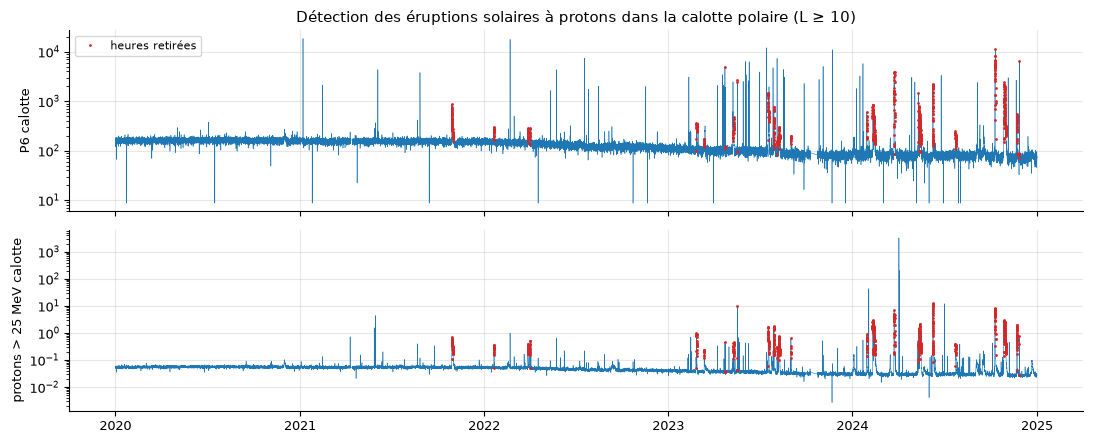

In [7]:
rapport_noaa = {'lignes au départ (heure x tranche de L)': len(noaa)}

# 1. Trous : une heure sans mesure n'a pas de flux (un flux nul, lui, est une vraie mesure)
noaa = noaa[noaa.n > 0].copy()
rapport_noaa['trous retirés (n = 0)'] = rapport_noaa['lignes au départ (heure x tranche de L)'] - len(noaa)

# 2. Pics aberrants : mesure de 2 s > PIC_MAX retirée de sa case horaire
PIC_MAX = 1e7
pic = noaa.p6_max > PIC_MAX
noaa.loc[pic, 'p6_sum'] -= noaa.loc[pic, 'p6_max']
noaa.loc[pic, 'n'] -= 1
noaa = noaa[noaa.n > 0]
rapport_noaa['cases avec un pic > 1e7 corrigées'] = int(pic.sum())

# 3. Protons solaires : P6 ou protons > 25 MeV de la calotte polaire > médiane + 10 MAD pendant >= 2 h,
#    masque élargi de +-1 h
SEP_K = 10
calotte = noaa[noaa.Lbin == L_POLAR].set_index('time')

def anormal(s, k=SEP_K):
    """True quand s dépasse médiane + k x MAD (MAD = écart absolu médian x 1,4826)."""
    med = s.median()
    return s > med + k * 1.4826 * (s - med).abs().median()

p6_calotte = calotte.p6_sum / calotte.n
p1_calotte = calotte.omni_p1_sum / calotte.omni_p1_n.where(calotte.omni_p1_n > 0)
sep = anormal(p6_calotte) | anormal(p1_calotte.dropna()).reindex(calotte.index, fill_value=False)
sep = sep.reindex(pd.date_range(START, END, freq='h', inclusive='left'), fill_value=False)   # grille horaire complète
sep = sep & (sep.shift(1, fill_value=False) | sep.shift(-1, fill_value=False))   # au moins 2 heures consécutives
h = sep.index[sep]
heures_sep = h.union(h - pd.Timedelta('1h')).union(h + pd.Timedelta('1h'))
avant = len(noaa)
noaa = noaa[~noaa.time.isin(heures_sep)]
rapport_noaa['heures contaminées par des protons'] = len(heures_sep)
rapport_noaa['lignes retirées (protons)'] = avant - len(noaa)
rapport_noaa['lignes gardées'] = len(noaa)

# 4. OMNI et synchronisation : même grille horaire, pas de doublon
assert omni.index.is_unique and omni.index.is_monotonic_increasing
assert (noaa.time == noaa.time.dt.floor('h')).all() and (omni.index == omni.index.floor('h')).all()
rapport_noaa['heures NOAA-15 absentes de la grille OMNI'] = int((~noaa.time.isin(omni.index)).sum())

for k, v in rapport_noaa.items():
    print(f'{k:<45}{v:>10}')
jours_sep = pd.Series(heures_sep.floor('D')).value_counts().sort_index()
print('Jours avec au moins 3 heures contaminées :', ', '.join(f'{d:%Y-%m-%d}' for d in jours_sep[jours_sep >= 3].index))

fig, ax = plt.subplots(2, 1, figsize=(11, 4.5), sharex=True)
for a, s, nom in ((ax[0], p6_calotte, 'P6 calotte'), (ax[1], p1_calotte, 'protons > 25 MeV calotte')):
    a.semilogy(s.index, s.clip(lower=s[s > 0].min()), lw=0.4, color='C0')
    m = s.index.isin(heures_sep)
    a.plot(s.index[m], s[m].clip(lower=s[s > 0].min()), '.', ms=2, color='C3', label='heures retirées')
    a.set_ylabel(nom)
ax[0].set_title('Détection des éruptions solaires à protons dans la calotte polaire (L ≥ 10)')
ax[0].legend(fontsize=8)
fig.tight_layout()
savefig(fig, '2_protons_solaires.png')
plt.show()

## 3. Choix de la région des ceintures de radiation (plage de L)

**Le paramètre L** : distance (en rayons terrestres) à laquelle la ligne de champ magnétique sur laquelle se trouve
le satellite croise l'équateur magnétique. NOAA-15 est en orbite basse (~810 km) mais, en passant d'un pôle à
l'autre, il traverse toutes les lignes de champ, donc toutes les valeurs de L. Le flux mesuré dépend énormément de L :
il faut choisir **quelle région** on cherche à prédire.

**Ce que dit la physique :**
* **L < 2 : ceinture interne.** Peuplée de protons piégés très énergétiques (Anomalie Sud-Atlantique) : P6 y compte
  surtout des **protons**, pas des électrons → à exclure.
* **L ≈ 2–3 : zone « slot ».** Quasi vide d'électrons, sauf après de très forts orages.
* **L ≈ 3–7 : ceinture externe.** C'est là que se trouvent les électrons relativistes (~1 MeV) qui varient fortement
  avec le vent solaire : c'est la région qui nous intéresse.
* **L > 7 :** on sort des ceintures (lignes de champ ouvertes ou très étirées) → flux au niveau du bruit.

**Critères de choix**, vérifiés sur les données 2020–2024 ci-dessous. La région retenue doit :
1. avoir un flux **nettement au-dessus du bruit de fond** de l'instrument (sinon on prédit du bruit) ;
2. être **variable** dans le temps (sinon il n'y a rien à prédire) ;
3. être **liée au vent solaire** (sinon les paramètres OMNI ne serviront à rien pour prédire).

### 3.1 Carte L – temps du flux
Pour chaque jour et chaque tranche de L, flux moyen = Σ flux / Σ mesures. L'échelle de couleur est logarithmique
(le flux varie sur plusieurs ordres de grandeur). L'indice Dst est tracé en dessous : les fortes valeurs négatives
signalent les orages géomagnétiques.

**Pixels isolés aberrants :** quelques cases (1 jour × 1 tranche de L) sont plus de 3 fois (0,5 en log10) au-dessus
ou en dessous **à la fois du jour d'avant et du jour d'après**, sans que les tranches de L voisines bougent. Ce n'est
pas de la physique : un vrai orage dure plusieurs jours et touche plusieurs tranches de L à la fois. Ce sont des
restes de mesures parasites (une poignée de mesures de 2 s anormales dans une case peu remplie). Pour la carte, ces
cases sont remplacées par la **moyenne du jour d'avant et du jour d'après** (même tranche de L).

Bruit de fond P6 (médiane horaire en calotte polaire) : 133 #/cm²/s/sr
Pixels isolés aberrants remplacés : 89 sur 50344


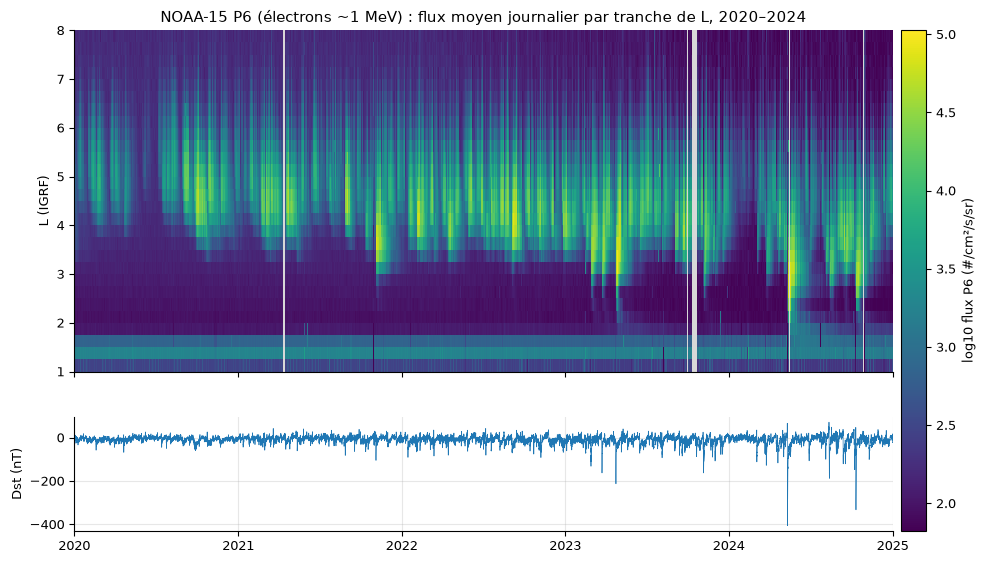

In [8]:
# Niveau de bruit : dans la calotte polaire (L >= 10) il n'y a pas d'électrons piégés,
# P6 n'y mesure que le bruit de fond de l'instrument
pc = noaa[noaa.Lbin == L_POLAR]
NOISE = (pc.p6_sum / pc.n).median()
print(f'Bruit de fond P6 (médiane horaire en calotte polaire) : {NOISE:.0f} #/cm²/s/sr')

# Moyenne journalière par tranche de L (L < 8)
belt = noaa[noaa.Lbin < L_POLAR]
d = belt.groupby([belt.time.dt.floor('D'), 'Lbin'])[['p6_sum', 'n']].sum()
carte = (d.p6_sum / d.n).unstack('Lbin')
carte = carte.reindex(pd.date_range(START, END, freq='D', inclusive='left'))   # jours manquants -> NaN

# Pixels isolés aberrants -> moyenne du jour d'avant et du jour d'après (même tranche de L)
log_carte = np.log10(carte.clip(lower=NOISE / 2))
avant, apres = log_carte.shift(1), log_carte.shift(-1)
SAUT = 0.5                                                 # facteur 10^0,5 ≈ 3

def isole_en_L(m):
    """Garde les pixels marqués dont aucune tranche de L voisine n'est marquée le même jour."""
    return m & ~(m.shift(1, axis=1, fill_value=False) | m.shift(-1, axis=1, fill_value=False))

aberrant = (isole_en_L(log_carte - np.fmax(avant, apres) > SAUT)      # pic isolé vers le haut
            | isole_en_L(np.fmin(avant, apres) - log_carte > SAUT))   # creux isolé vers le bas
voisins = (avant.fillna(apres) + apres.fillna(avant)) / 2
log_carte = log_carte.mask(aberrant, voisins)
print(f'Pixels isolés aberrants remplacés : {int(aberrant.values.sum())} sur {int(carte.notna().values.sum())}')

fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
cmap = plt.get_cmap('viridis').copy()
cmap.set_bad('0.85')                                      # jours manquants en gris
im = ax[0].imshow(log_carte.T.values, aspect='auto', origin='lower', cmap=cmap,
                  extent=[mdates.date2num(START), mdates.date2num(END), 1, 8], interpolation='nearest')
ax[0].grid(False)
ax[0].set_ylabel('L (IGRF)')
ax[0].set_title('NOAA-15 P6 (électrons ~1 MeV) : flux moyen journalier par tranche de L, 2020–2024')
fig.colorbar(im, ax=ax, label='log10 flux P6 (#/cm²/s/sr)', pad=0.01, fraction=0.03)
ax[1].plot(omni.index, omni['Dst_nT'], color='C0', lw=0.5)
ax[1].set_ylabel('Dst (nT)')
ax[1].xaxis_date()
savefig(fig, '3_carte_L_temps.png')
plt.show()

### 3.2 Profil en L : niveau, variabilité et lien avec le vent solaire
On calcule, pour chaque tranche de L, le flux moyen sur des fenêtres de 12 h (la résolution du projet), puis :
* le **flux moyen** (linéaire) → sert au choix automatique de la région ;
* la **médiane** et les percentiles 5 % / 95 % du log10 du flux → niveau par rapport au bruit (critère 1) ;
* le **% de fenêtres où le flux dépasse 2 × le bruit** (critère 1) ;
* l'**écart-type du log10 du flux** → variabilité (critère 2) ;
* la **corrélation de Spearman** entre le log10 du flux et la vitesse du vent solaire V **24 h plus tôt**
  (le vent solaire met 1 à 2 jours à accélérer les électrons) → lien avec le vent solaire (critère 3).

Flux moyen maximal : 6119 #/cm²/s/sr pour 4.25 <= L < 4.5
Région retenue automatiquement : 3.5 <= L < 5.25


,flux moyen,log10 P5,log10 médiane,log10 P95,% > 2×bruit,écart-type log10,Spearman V(t-24h)
L (bord gauche),,,,,,,
1,310.9,2.1,2.44,2.84,56.9,0.2,-0.05
1.25,"1,748",2.92,3.19,3.42,99.38,0.2,-0.04
1.5,713.3,2.61,2.89,3.05,98.71,0.18,-0.08
1.75,186.5,1.97,2.07,2.74,9.77,0.25,0.02
2,154.7,1.87,1.97,2.38,4.65,0.22,-0.03
2.25,222.8,1.84,1.98,2.2,3.11,0.24,-0.02
2.5,523.6,1.87,2.02,2.56,5.68,0.35,-0.02
2.75,"1,050",1.9,2.07,3.33,12.69,0.47,0.02
3,"1,740",1.96,2.14,3.84,22.51,0.59,0.16


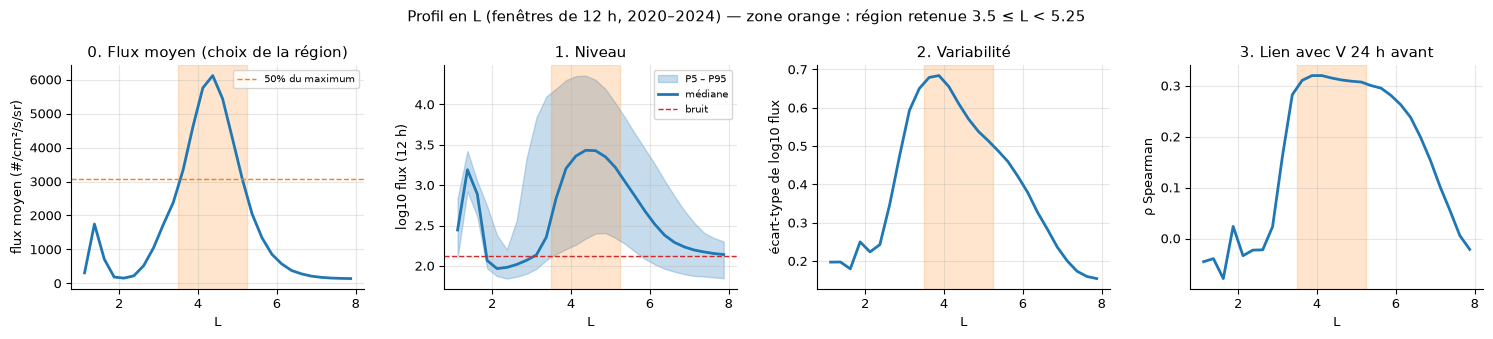

In [9]:
d12 = belt.groupby([pd.Grouper(key='time', freq=STEP), 'Lbin'])[['p6_sum', 'n']].sum()
f12 = (d12.p6_sum / d12.n).unstack('Lbin')                # flux 12 h : une colonne par tranche de L
logf = np.log10(f12.clip(lower=NOISE / 2))
V12 = omni['V_kms'].resample(STEP).mean()

profil = pd.DataFrame({
    'flux moyen': f12.mean(),
    'log10 P5': logf.quantile(0.05),
    'log10 médiane': logf.median(),
    'log10 P95': logf.quantile(0.95),
    '% > 2×bruit': (f12 > 2 * NOISE).mean() * 100,
    'écart-type log10': logf.std(),
    'Spearman V(t-24h)': logf.apply(lambda c: c.corr(V12.shift(2).reindex(c.index), method='spearman')),
})
profil.index.name = 'L (bord gauche)'

# Choix automatique de la région : largeur à mi-hauteur du profil de flux moyen.
# On part de la tranche où le flux moyen est maximal, puis on ajoute les tranches voisines
# tant que leur flux moyen reste >= SEUIL_REGION x le maximum.
SEUIL_REGION = 0.5
LBIN_W = 0.25                                             # largeur d'une tranche de L
flux_moy = profil['flux moyen']
garde = (flux_moy >= SEUIL_REGION * flux_moy.max()).values
lo = hi = flux_moy.index.get_loc(flux_moy.idxmax())
while lo > 0 and garde[lo - 1]:
    lo -= 1
while hi < len(garde) - 1 and garde[hi + 1]:
    hi += 1
L_LO, L_HI = flux_moy.index[lo], flux_moy.index[hi] + LBIN_W

print(f'Flux moyen maximal : {flux_moy.max():.0f} #/cm²/s/sr pour {flux_moy.idxmax()} <= L < {flux_moy.idxmax() + LBIN_W}')
print(f'Région retenue automatiquement : {L_LO} <= L < {L_HI}')
display(profil.round(2))

x = profil.index + LBIN_W / 2                             # centre des tranches
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
ax[0].plot(x, profil['flux moyen'], color='C0', lw=2)
ax[0].axhline(SEUIL_REGION * flux_moy.max(), color='C1', ls='--', label=f'{SEUIL_REGION:.0%} du maximum')
ax[0].set_ylabel('flux moyen (#/cm²/s/sr)')
ax[0].set_title('0. Flux moyen (choix de la région)')
ax[0].legend(fontsize=7)
ax[1].fill_between(x, profil['log10 P5'], profil['log10 P95'], color='C0', alpha=0.25, label='P5 – P95')
ax[1].plot(x, profil['log10 médiane'], color='C0', lw=2, label='médiane')
ax[1].axhline(np.log10(NOISE), color='C3', ls='--', label='bruit')
ax[1].set_ylabel('log10 flux (12 h)')
ax[1].set_title('1. Niveau')
ax[1].legend(fontsize=7)
ax[2].plot(x, profil['écart-type log10'], color='C0', lw=2)
ax[2].set_ylabel('écart-type de log10 flux')
ax[2].set_title('2. Variabilité')
ax[3].plot(x, profil['Spearman V(t-24h)'], color='C0', lw=2)
ax[3].set_ylabel('ρ Spearman')
ax[3].set_title('3. Lien avec V 24 h avant')
for a in ax:
    a.axvspan(L_LO, L_HI, color='C1', alpha=0.2)
    a.set_xlabel('L')
fig.suptitle(f'Profil en L (fenêtres de 12 h, 2020–2024) — zone orange : région retenue {L_LO} ≤ L < {L_HI}')
fig.tight_layout()
savefig(fig, '3_profil_L.png')
plt.show()

### 3.3 Conclusion : vérification de la région choisie automatiquement

**Règle de choix (codée en 3.2) :** la région est la **largeur à mi-hauteur** du profil de flux moyen. On part de
la tranche de L où le flux moyen est maximal (le cœur de la ceinture externe) et on garde les tranches voisines
tant que leur flux moyen reste au moins égal à la moitié du maximum. Aucune valeur de L n'est rentrée à la main ;
le seul paramètre est `SEUIL_REGION = 0.5` (la « mi-hauteur »).

**Ce que montre la carte L – temps (3.1) :**
* une bande **constante à L ≈ 1,25–1,75** : les protons de la ceinture interne, insensibles aux orages → exclue ;
* une **zone « slot » sombre à L ≈ 2–3**, remplie seulement lors des orages les plus forts (2023, mai 2024 :
  Dst ≈ −400 nT), quand la ceinture externe est poussée vers la Terre ;
* une **ceinture externe à L ≈ 3,5–6** qui s'allume et s'éteint au rythme de l'activité solaire : c'est la cible ;
* au-delà de L ≈ 7, le flux reste au niveau du bruit.

La cellule ci-dessous vérifie que la région retenue remplit les trois critères (flux moyenné sur toute la région,
fenêtres de 12 h) et la compare aux deux régions décalées d'une demi-unité de L.

In [10]:
def criteres(lo, hi):
    """Les 3 critères du point 3 pour la région lo <= L < hi (flux 12 h moyenné sur toute la région)."""
    g = belt[(belt.Lbin >= lo) & (belt.Lbin < hi)].groupby(pd.Grouper(key='time', freq=STEP))[['p6_sum', 'n']].sum()
    f = (g.p6_sum / g.n).dropna()
    lf = np.log10(f.clip(lower=NOISE / 2))
    return {'flux moyen': f.mean(),
            '% > 2×bruit': (f > 2 * NOISE).mean() * 100,
            'écart-type log10': lf.std(),
            'Spearman V(t-24h)': lf.corr(V12.shift(2).reindex(lf.index), method='spearman')}

regions = {f'{L_LO - 0.5} ≤ L < {L_HI - 0.5}': criteres(L_LO - 0.5, L_HI - 0.5),
           f'{L_LO} ≤ L < {L_HI} (retenue)': criteres(L_LO, L_HI),
           f'{L_LO + 0.5} ≤ L < {L_HI + 0.5}': criteres(L_LO + 0.5, L_HI + 0.5)}
display(pd.DataFrame(regions).T.round(2))

,flux moyen,% > 2×bruit,écart-type log10,Spearman V(t-24h)
3.0 ≤ L < 4.75,"3,890",88.97,0.6,0.34
3.5 ≤ L < 5.25 (retenue),"4,657",93.48,0.56,0.35
4.0 ≤ L < 5.75,"4,232",94.9,0.53,0.33


**Lecture (2020–2024) : la règle donne 3,5 ≤ L < 5,25**, centrée sur le maximum du flux moyen (L ≈ 4,25–4,5).
Moyennée sur toute la région, elle remplit les trois critères :
1. flux **au-dessus de 2 × le bruit dans 93 % des fenêtres** de 12 h ;
2. **variabilité** forte (écart-type de log10 flux ≈ 0,56) : il y a quelque chose à prédire ;
3. **lien avec le vent solaire** (Spearman avec V 24 h avant ≈ 0,35), au moins aussi bon que ses voisines.

C'est aussi la région qui a le **flux moyen le plus élevé** des trois. Décalée vers le bas (3–4,75), elle déborde
sur le « slot » et passe plus souvent dans le bruit (89 %) ; décalée vers le haut (4–5,75), le flux moyen et la
variabilité baissent.

Limite : la ceinture se déplace (vers la Terre pendant les forts orages). Une plage fixe ne la suit pas toujours ;
comparer plusieurs plages de L est d'ailleurs proposé en bonus par l'énoncé.

## 4. Moyennes sur 12 h

Toutes les données sont ramenées sur des **fenêtres de 12 h** (00:00–12:00 et 12:00–24:00 UTC), la résolution des
prédictions du Step 2 :
* **flux** : on garde les tranches de la région retenue (`L_LO ≤ L < L_HI`, point 3) et on calcule
  flux 12 h = Σ `p6_sum` / Σ `n`, c'est-à-dire la moyenne du **flux linéaire** de toutes les mesures de la
  fenêtre (puis son log10). Une fenêtre est déclarée **invalide** (NaN) si elle contient moins de 25 % du nombre
  médian de mesures : trop peu de passages dans la région pour que la moyenne soit fiable ;
* `couverture` = nombre d'heures de la fenêtre où NOAA-15 est passé dans la région / 12 ;
* **paramètres OMNI** : moyenne sur la fenêtre, NaN s'il y a moins de 6 heures valides sur 12.

La table est enregistrée dans `data/table_12h.parquet` : c'est l'**entrée du Step 2**.

In [11]:
fen = pd.date_range(START, END, freq=STEP, inclusive='left')   # début de chaque fenêtre de 12 h

# Flux de la région : somme des flux / nombre de mesures sur chaque fenêtre
reg = noaa[(noaa.Lbin >= L_LO) & (noaa.Lbin < L_HI)]
g = reg.groupby(pd.Grouper(key='time', freq=STEP))[['p6_sum', 'n']].sum().reindex(fen, fill_value=0)
heures = reg.groupby(pd.Grouper(key='time', freq=STEP)).time.nunique().reindex(fen, fill_value=0)
N_MIN = 0.25 * g.n[g.n > 0].median()
flux12 = (g.p6_sum / g.n).where(g.n >= N_MIN)

# OMNI : moyenne sur 12 h si au moins 6 heures valides
omni12 = omni.resample(STEP).mean().where(omni.resample(STEP).count() >= 6).reindex(fen)

tab = pd.DataFrame({'flux': flux12, 'log_flux': np.log10(flux12), 'n': g.n, 'couverture': heures / 12})
tab = tab.join(omni12)
tab.index.name = 'time'
tab.to_parquet(os.path.join(DATA, 'table_12h.parquet'))

print(f'Région {L_LO} <= L < {L_HI} : {len(tab)} fenêtres de 12 h, '
      f'{tab.flux.isna().sum()} sans flux valide (seuil : {N_MIN:.0f} mesures)')
print('% manquant par colonne :', tab.isna().mean().mul(100).round(1).to_dict())
tab.head()

Région 3.5 <= L < 5.25 : 3654 fenêtres de 12 h, 110 sans flux valide (seuil : 393 mesures)
% manquant par colonne : {'flux': 3.0, 'log_flux': 3.0, 'n': 0.0, 'couverture': 0.0, 'V_kms': 1.1, 'Bz_nT': 0.6, 'F107_sfu': 0.1, 'N_cm3': 1.2, 'P_nPa': 1.2, 'E_mVm': 1.3, 'B_nT': 0.6, 'Kp': 0.0, 'Dst_nT': 0.0, 'AE_nT': 0.0}


,flux,log_flux,n,couverture,V_kms,Bz_nT,F107_sfu,N_cm3,P_nPa,E_mVm,B_nT,Kp,Dst_nT,AE_nT
time,,,,,,,,,,,,,,
2020-01-01 00:00:00,644.5,2.809,1838,1,312,-0.5167,69.4,7.883,1.373,0.1725,4.092,0.25,1.833,22.92
2020-01-01 12:00:00,631.5,2.8,1633,1,324.1,0.125,69.4,10.48,1.915,-0.03583,3.542,0.925,2.167,72.25
2020-01-02 00:00:00,596,2.775,1855,1,318.1,0.2,69.5,9.4,1.625,-0.0625,3.7,0.15,3.083,37.08
2020-01-02 12:00:00,618.5,2.791,1512,1,347.3,-0.1,69.5,6.608,1.403,0.02667,3.042,0.75,-1.333,62.25
2020-01-03 00:00:00,626.3,2.797,1922,1,346,-0.7667,68.9,13.78,2.776,0.2542,5.258,1.6,1.417,117.1


## 5. Visualisation des séries temporelles

### 5.1 Flux d'électrons en fonction du temps

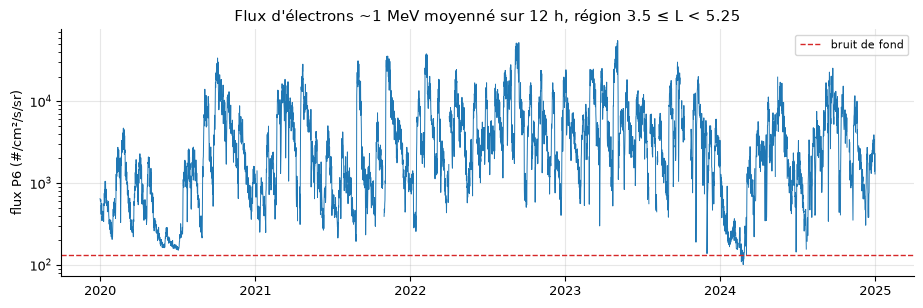

In [12]:
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.semilogy(tab.index, tab.flux, lw=0.7, color='C0')
ax.axhline(NOISE, color='C3', ls='--', lw=1, label='bruit de fond')
ax.set_ylabel('flux P6 (#/cm²/s/sr)')
ax.set_title(f'Flux d\'électrons ~1 MeV moyenné sur 12 h, région {L_LO} ≤ L < {L_HI}')
ax.legend(fontsize=8)
savefig(fig, '5_flux_temps.png')
plt.show()

### 5.2 L en fonction du temps
En haut : position de NOAA-15 en L heure par heure sur deux jours (couleur = nombre de mesures de 2 s dans chaque
case heure × tranche de L, échelle log). En ~25 min, le satellite va de l'équateur (L ≈ 1) au pôle (L > 10) : il
traverse donc **toutes les valeurs de L plusieurs fois par heure**, la région retenue (lignes rouges) comprise. Il
passe plus de temps à bas L (près de l'équateur, les lignes de champ défilent lentement). En bas : nombre de mesures
dans la région par fenêtre de 12 h, sur les 5 ans (les creux = jours sans données ou heures retirées).

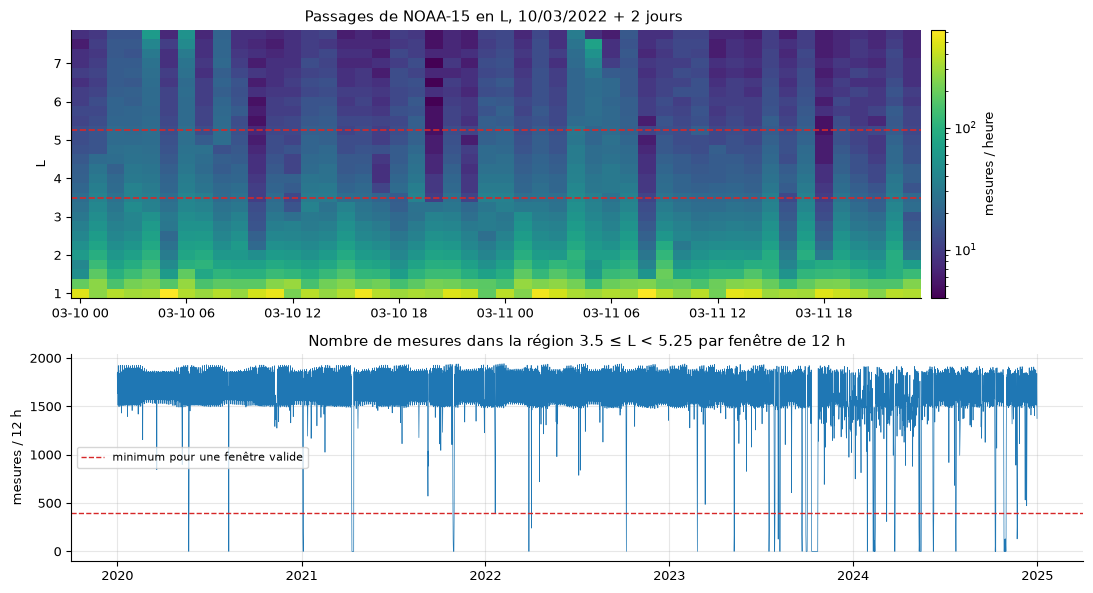

In [13]:
from matplotlib.colors import LogNorm

J0 = pd.Timestamp('2022-03-10')
deux_jours = noaa[(noaa.time >= J0) & (noaa.time < J0 + pd.Timedelta('2D')) & (noaa.Lbin < L_POLAR)]
pos = deux_jours.pivot_table(index='Lbin', columns='time', values='n', aggfunc='sum')

fig, ax = plt.subplots(2, 1, figsize=(11, 6), gridspec_kw={'height_ratios': [1.3, 1]})
im = ax[0].pcolormesh(mdates.date2num(pos.columns), pos.index, pos.values, cmap='viridis', shading='nearest',
                     norm=LogNorm())
fig.colorbar(im, ax=ax[0], label='mesures / heure', pad=0.01)
for l in (L_LO, L_HI):
    ax[0].axhline(l, color='C3', ls='--', lw=1.2)
ax[0].xaxis_date()
ax[0].grid(False)
ax[0].set_ylabel('L')
ax[0].set_title(f'Passages de NOAA-15 en L, {J0:%d/%m/%Y} + 2 jours ')
ax[1].plot(tab.index, tab.n, lw=0.5, color='C0')
ax[1].axhline(N_MIN, color='C3', ls='--', lw=1, label='minimum pour une fenêtre valide')
ax[1].set_ylabel('mesures / 12 h')
ax[1].set_title(f'Nombre de mesures dans la région {L_LO} ≤ L < {L_HI} par fenêtre de 12 h')
ax[1].legend(fontsize=8)
fig.tight_layout()
savefig(fig, '5_L_temps.png')
plt.show()

### 5.3 Paramètres solaires en fonction du temps
Le flux (en haut) est tracé avec les paramètres solaires et géomagnétiques pour les comparer à l'œil : vitesse du
vent solaire V, composante Bz du champ magnétique interplanétaire, flux radio solaire F10.7 (activité du Soleil,
qui augmente sur 2020–2024 : montée du cycle 25), indices Kp et Dst (orages géomagnétiques : Dst très négatif).

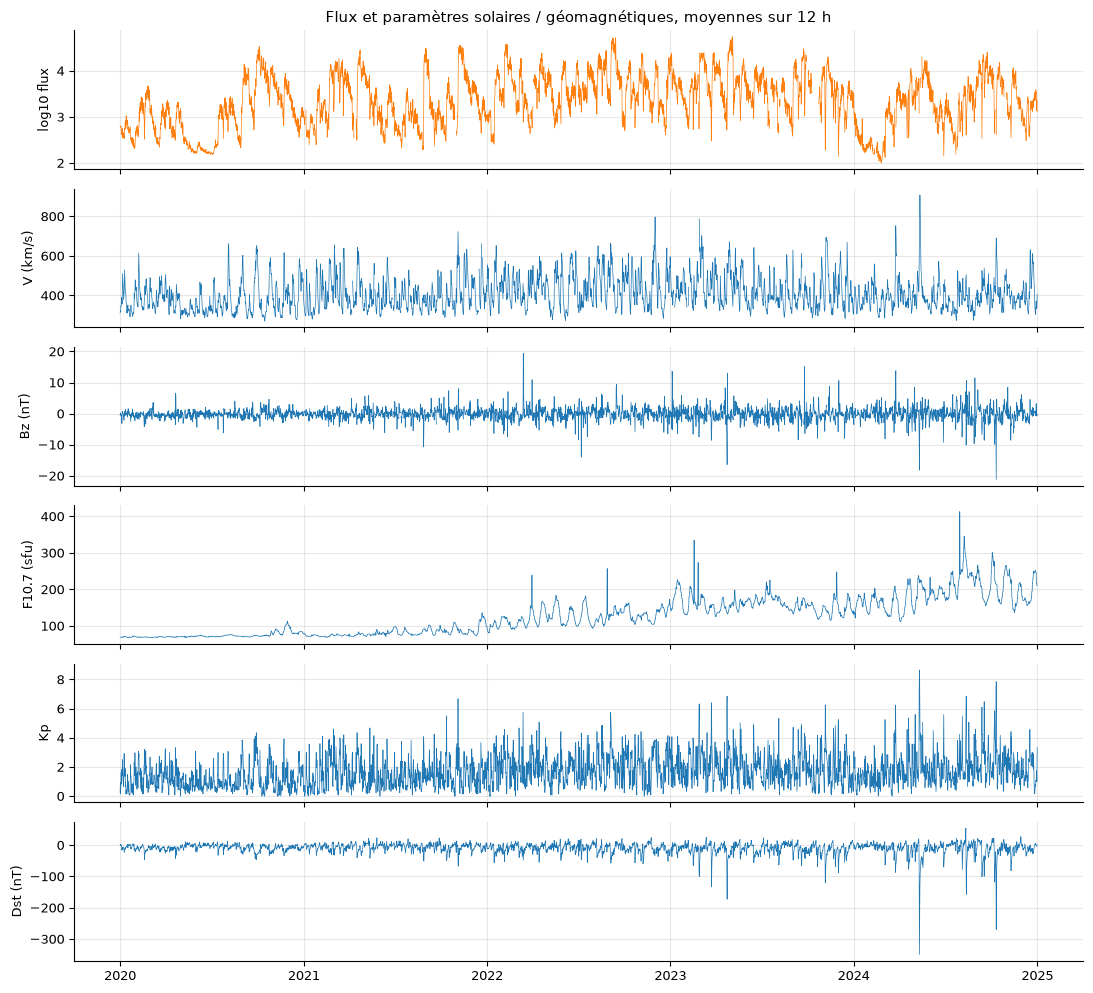

In [14]:
series = [('log_flux', 'log10 flux'), ('V_kms', 'V (km/s)'), ('Bz_nT', 'Bz (nT)'),
          ('F107_sfu', 'F10.7 (sfu)'), ('Kp', 'Kp'), ('Dst_nT', 'Dst (nT)')]
fig, ax = plt.subplots(len(series), 1, figsize=(11, 10), sharex=True)
for a, (col, nom) in zip(ax, series):
    a.plot(tab.index, tab[col], lw=0.5, color='C1' if col == 'log_flux' else 'C0')
    a.set_ylabel(nom)
ax[0].set_title('Flux et paramètres solaires / géomagnétiques, moyennes sur 12 h')
fig.tight_layout()
savefig(fig, '5_parametres_solaires.png')
plt.show()

## 6. Statistiques descriptives, relations, outliers

### 6.1 Statistiques descriptives

,count,mean,std,min,25%,50%,75%,max
flux,"3,544","4,675","6,206",100.9,902.5,"2,338","5,992",5.521e+04
log_flux,"3,544",3.351,0.559,2.004,2.955,3.369,3.778,4.742
n,"3,654","1,613",347.7,0,"1,513","1,568","1,856","1,942"
couverture,"3,654",0.9556,0.1765,0,1,1,1,1
V_kms,"3,612",410.4,84.34,270.2,345.7,392.9,458.9,908.1
Bz_nT,"3,631",-0.1145,2.159,-21.18,-1.075,-0.1417,0.8417,19.42
F107_sfu,"3,652",126.4,51.48,67.4,76.5,121.2,162,412.9
N_cm3,"3,611",6.354,4.348,0.2417,3.35,5.108,8.087,54.35
P_nPa,"3,611",1.885,1.419,0.09667,1.124,1.554,2.183,29.94
E_mVm,"3,607",0.05115,0.967,-10.46,-0.3421,0.0575,0.4383,14.36


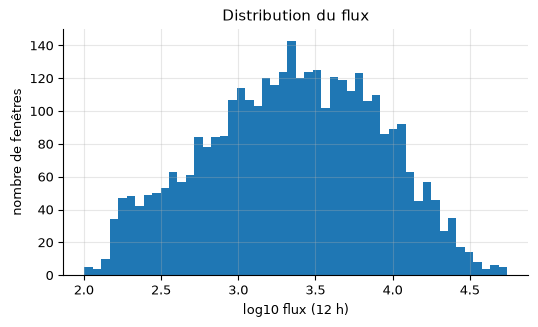

In [15]:
display(tab.describe().T)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(tab.log_flux.dropna(), bins=50, color='C0')
ax.set_xlabel('log10 flux (12 h)')
ax.set_ylabel('nombre de fenêtres')
ax.set_title('Distribution du flux')
savefig(fig, '6_histogramme_flux.png')
plt.show()

### 6.2 Relations entre le flux et les paramètres solaires
Corrélation de **Spearman** (sur les rangs : elle mesure une relation monotone, même non linéaire, et elle est peu
sensible aux valeurs extrêmes), entre toutes les colonnes au même instant t.

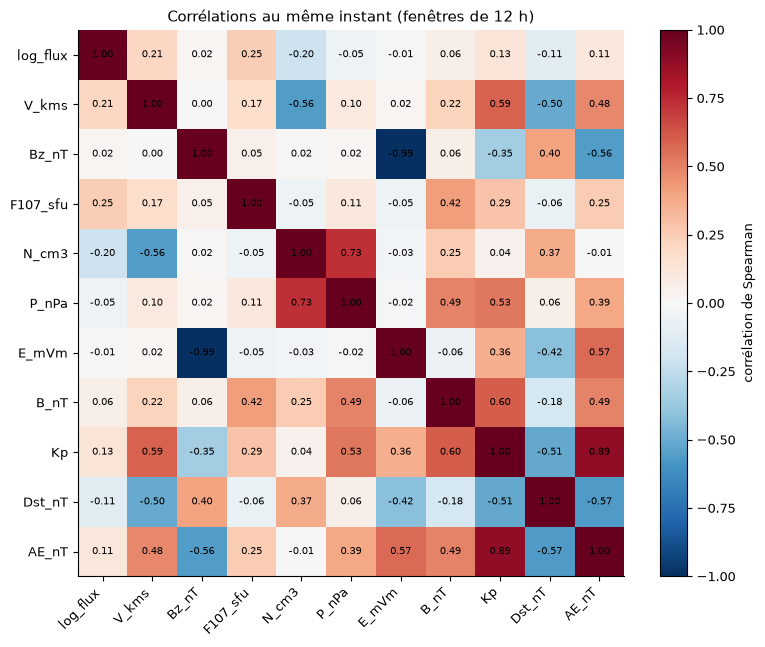

In [16]:
COLS = ['log_flux', 'V_kms', 'Bz_nT', 'F107_sfu', 'N_cm3', 'P_nPa', 'E_mVm', 'B_nT', 'Kp', 'Dst_nT', 'AE_nT']
corr = tab[COLS].corr(method='spearman')

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(COLS)))
ax.set_xticklabels(COLS, rotation=45, ha='right')
ax.set_yticks(range(len(COLS)))
ax.set_yticklabels(COLS)
ax.grid(False)
for i in range(len(COLS)):
    for j in range(len(COLS)):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(im, ax=ax, label='corrélation de Spearman')
ax.set_title('Corrélations au même instant (fenêtres de 12 h)')
fig.tight_layout()
savefig(fig, '6_correlations.png')
plt.show()

### 6.3 Corrélations retardées
Le flux d'électrons réagit au vent solaire **avec retard** (les électrons sont accélérés en 1 à 2 jours). On calcule
donc la corrélation entre le flux à t et chaque paramètre à **t − k × 12 h** (k = 0 à 8, soit jusqu'à 4 jours
avant). C'est ce qui indique quels paramètres seront utiles pour prédire le flux à +12 → +48 h.

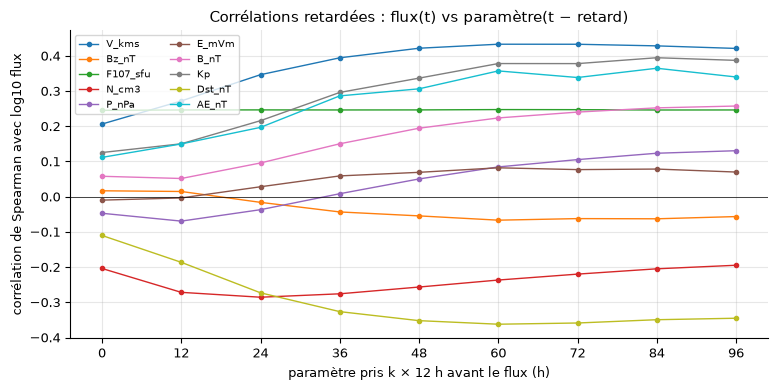

,retard le plus corrélé (h),corrélation
V_kms,60,0.43
Kp,84,0.39
AE_nT,84,0.36
Dst_nT,60,-0.36
N_cm3,24,-0.29
B_nT,96,0.26
F107_sfu,60,0.25
P_nPa,96,0.13
E_mVm,60,0.08
Bz_nT,60,-0.07


In [17]:
LAGS = range(0, 9)
lag = pd.DataFrame({c: [tab.log_flux.corr(tab[c].shift(k), method='spearman') for k in LAGS]
                    for c in COLS if c != 'log_flux'}, index=[12 * k for k in LAGS])
lag.index.name = 'retard (h)'

fig, ax = plt.subplots(figsize=(9, 4))
for c in lag.columns:
    ax.plot(lag.index, lag[c], 'o-', ms=3, label=c)
ax.axhline(0, color='k', lw=0.5)
ax.set_xticks(lag.index)
ax.set_xlabel('paramètre pris k × 12 h avant le flux (h)')
ax.set_ylabel('corrélation de Spearman avec log10 flux')
ax.set_title('Corrélations retardées : flux(t) vs paramètre(t − retard)')
ax.legend(fontsize=7, ncol=2)
savefig(fig, '6_correlations_retardees.png')
plt.show()

meilleur = pd.DataFrame({'retard le plus corrélé (h)': lag.abs().idxmax(),
                         'corrélation': [lag.loc[lag[c].abs().idxmax(), c] for c in lag.columns]})
display(meilleur.sort_values('corrélation', key=abs, ascending=False).round(2))

**Lecture :**
* la **vitesse du vent solaire V** est le meilleur indicateur, avec un **retard de 2,5 à 3 jours** (ρ ≈ 0,43) :
  un vent rapide aujourd'hui annonce un flux élevé 2–3 jours plus tard (temps d'accélération des électrons) ;
* **Kp, AE** (activité géomagnétique, ρ ≈ 0,4 à ~3,5 jours) et **Dst** (ρ ≈ −0,36 : un orage, Dst < 0, précède une
  hausse du flux) vont dans le même sens ;
* la **densité N** est anti-corrélée (ρ ≈ −0,29 à 24 h) : un vent dense et lent va avec un flux plus faible ;
* **Bz** est peu corrélé en moyenne 12 h : son signe change très vite, la moyenne efface son effet.

→ Pour le Step 2, les valeurs passées de V, Kp, AE, Dst et N sur les 1 à 4 derniers jours sont les entrées les plus
utiles.

### 6.4 Valeurs extrêmes (outliers)
Règle de l'écart interquartile (IQR) appliquée à chaque colonne de la table 12 h : une valeur est extrême si elle
sort de [Q1 − 1,5·IQR ; Q3 + 1,5·IQR]. On regarde ensuite **quand** elles se produisent : si elles tombent pendant
des orages géomagnétiques (Dst très négatif), ce sont de **vrais phénomènes physiques**, pas des erreurs.

In [18]:
q1, q3 = tab[COLS].quantile(0.25), tab[COLS].quantile(0.75)
iqr = q3 - q1
extreme = (tab[COLS] < q1 - 1.5 * iqr) | (tab[COLS] > q3 + 1.5 * iqr)
display(pd.DataFrame({'fenêtres extrêmes': extreme.sum(), '%': (extreme.mean() * 100).round(1)}).T)

# Les fenêtres les plus extrêmes du vent solaire et du Dst : à quelles dates ?
print('5 fenêtres de Dst le plus négatif :')
display(tab.nsmallest(5, 'Dst_nT')[['log_flux', 'V_kms', 'Bz_nT', 'Kp', 'Dst_nT']].round(2))
orage = tab.Dst_nT < -50
print(f'Part des fenêtres extrêmes en V, Bz ou Kp tombant pendant un orage (Dst < -50 nT) : '
      f'{orage[extreme[["V_kms", "Bz_nT", "Kp"]].any(axis=1)].mean():.0%} '
      f'(contre {orage.mean():.0%} de toutes les fenêtres)')

,log_flux,V_kms,Bz_nT,F107_sfu,N_cm3,P_nPa,E_mVm,B_nT,Kp,Dst_nT,AE_nT
fenêtres extrêmes,0,60,221,16,162,229,220,150,59,157,183
%,0,1.6,6,0.4,4.4,6.3,6,4.1,1.6,4.3,5


5 fenêtres de Dst le plus négatif :


,log_flux,V_kms,Bz_nT,Kp,Dst_nT
time,,,,,
2024-05-11 00:00:00,NaN,716.2,-18.18,8.65,-349.3
2024-10-11 00:00:00,2.61,690,-21.18,7.85,-269.5
2024-05-11 12:00:00,NaN,838.2,-5.86,8.1,-223.8
2023-04-24 00:00:00,3.17,562.8,-16.41,6.85,-172.7
2024-08-12 12:00:00,2.64,467.7,-6.55,6.85,-157.3


Part des fenêtres extrêmes en V, Bz ou Kp tombant pendant un orage (Dst < -50 nT) : 23% (contre 3% de toutes les fenêtres)


**Lecture :**
* le **log10 du flux n'a aucune valeur extrême** : en échelle log, sa distribution est compacte (le flux varie sur
  2,7 ordres de grandeur, de 10² à 5·10⁴, sans valeur isolée) ;
* les valeurs extrêmes des paramètres solaires (V, Bz, Kp…) tombent **7 fois plus souvent pendant un orage**
  (23 % contre 3 %) : ce sont de **vrais phénomènes physiques** (tempête de mai 2024 : Dst = −349 nT, Kp = 8,7 ;
  octobre 2024 : Dst = −270 nT). On les **garde** : ce sont justement les situations qu'on veut savoir prédire ;
* pendant la tempête de mai 2024, le flux est manquant : une éruption à protons solaires a lieu en même temps et
  ces heures ont été retirées au point 2.3 (P6 ne mesurait plus des électrons).

## 7. Seuil du 95ᵉ percentile : définition des « événements »
Un **événement** est une fenêtre de 12 h où le flux dépasse le **95ᵉ percentile** de tous les flux 12 h : par
construction, 5 % des fenêtres. Des fenêtres consécutives au-dessus du seuil forment un même épisode.

⚠️ Pour le Step 2, ce seuil sera **recalculé sur la seule période d'entraînement** : le calculer sur toute la période
utiliserait de l'information sur le futur (le test).

Seuil P95 = 17006 #/cm²/s/sr (log10 = 4.23)
178 fenêtres au-dessus du seuil (5.0%), regroupées en 74 épisodes
Épisodes par année : {2020: 7, 2021: 13, 2022: 25, 2023: 21, 2024: 8}


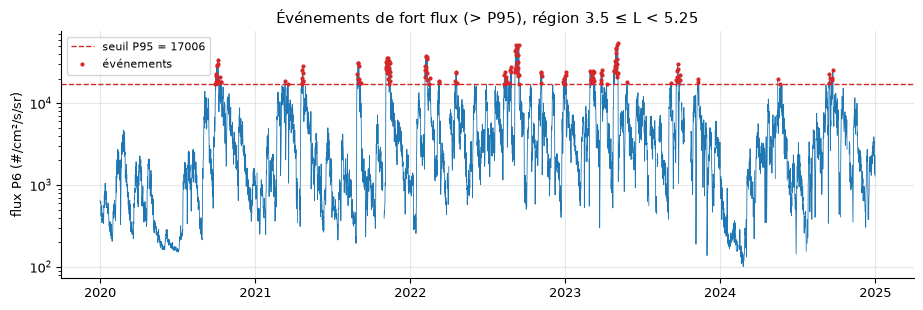

,début,fenêtres de 12 h,flux max
flux,,,
57,2023-04-27 00:00:00,18,5.521e+04
41,2022-09-05 00:00:00,20,5.215e+04
21,2022-02-05 00:00:00,11,3.798e+04
18,2021-11-05 00:00:00,15,3.569e+04
3,2020-10-04 00:00:00,1,3.382e+04
14,2021-08-31 00:00:00,5,3.122e+04
20,2021-11-14 00:00:00,4,3.073e+04
4,2020-10-05 00:00:00,2,3.025e+04
62,2023-09-22 12:00:00,5,3.014e+04


In [19]:
SEUIL_P95 = np.percentile(tab.flux.dropna(), P_EVENT)
evenement = tab.flux > SEUIL_P95
episode = (evenement & ~evenement.shift(fill_value=False)).cumsum()[evenement]   # numéro d'épisode
episodes = pd.DataFrame({'début': episode.index.to_series().groupby(episode).min(),
                         'fenêtres de 12 h': episode.groupby(episode).size(),
                         'flux max': tab.flux[evenement].groupby(episode).max().round(0)})

print(f'Seuil P{P_EVENT} = {SEUIL_P95:.0f} #/cm²/s/sr (log10 = {np.log10(SEUIL_P95):.2f})')
print(f'{evenement.sum()} fenêtres au-dessus du seuil ({evenement.sum() / tab.flux.notna().sum():.1%}), '
      f'regroupées en {len(episodes)} épisodes')
print('Épisodes par année :', episodes['début'].dt.year.value_counts().sort_index().to_dict())

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.semilogy(tab.index, tab.flux, lw=0.6, color='C0')
ax.axhline(SEUIL_P95, color='C3', ls='--', label=f'seuil P{P_EVENT} = {SEUIL_P95:.0f}')
ax.plot(tab.index[evenement], tab.flux[evenement], '.', ms=4, color='C3', label='événements')
ax.set_ylabel('flux P6 (#/cm²/s/sr)')
ax.set_title(f'Événements de fort flux (> P{P_EVENT}), région {L_LO} ≤ L < {L_HI}')
ax.legend(fontsize=8)
savefig(fig, '7_seuil_P95.png')
plt.show()
episodes.sort_values('flux max', ascending=False).head(10)

In [20]:
# Classification: event detection
# Goal: predict the probability of a high-flux event (flux above the 95th percentile)
# Suggested models: Logistic Regression, Support Vector Machine (SVM), Random Forest Classifier
# Evaluate using Accuracy, F1-score, AUC and the confusion matrix.
# Plot ROC curves and discuss the strengths and limitations of each model.
from sklearn.preprocessing import StandardScaler

donnees = tab[tab.flux.notna()].copy()          # une fenetre sans flux n'a pas d'etiquette

# Split the data chronologically (train / val / test): 70% train, 15% val, 15% test.
# Chronological and not random: two neighbouring 12 h windows look alike, a random split
# would put "the day before" of nearly every test window inside the training set.
fractions = (0.7, 0.15, 0.15)
f = np.asarray(fractions, float)
f = f / f.sum()
n = len(donnees)
i1, i2 = int(round(n * f[0])), int(round(n * (f[0] + f[1])))
tab_train = donnees.iloc[:i1].copy()
tab_val = donnees.iloc[i1:i2].copy()
tab_test = donnees.iloc[i2:].copy()

# The threshold comes from the TRAINING data only: computing it on the whole period
# would use information about the future (the test set) to define the classes.
SEUIL_P95 = np.percentile(tab_train.flux, 95)

# Event labels
y_train = (tab_train.flux > SEUIL_P95).astype(int)
y_val = (tab_val.flux > SEUIL_P95).astype(int)
y_test = (tab_test.flux > SEUIL_P95).astype(int)

print(f'Seuil P95 (entrainement seul) : {SEUIL_P95:.0f} #/cm2/s/sr '
      f'(log10 = {np.log10(SEUIL_P95):.2f})')
print(f'Entrainement : {tab_train.index.min():%Y-%m-%d} -> {tab_train.index.max():%Y-%m-%d}')
print(f'Validation   : {tab_val.index.min():%Y-%m-%d} -> {tab_val.index.max():%Y-%m-%d}')
print(f'Test         : {tab_test.index.min():%Y-%m-%d} -> {tab_test.index.max():%Y-%m-%d}')
print()
# Check class distribution
print(f'Training set: {len(y_train)} windows, {y_train.sum()} events ({y_train.mean():.2%})')
print(f'Validation set: {len(y_val)} windows, {y_val.sum()} events ({y_val.mean():.2%})')
print(f'Test set: {len(y_test)} windows, {y_test.sum()} events ({y_test.mean():.2%})')


Seuil P95 (entrainement seul) : 18727 #/cm2/s/sr (log10 = 4.27)
Entrainement : 2020-01-01 -> 2023-06-06
Validation   : 2023-06-07 -> 2024-03-26
Test         : 2024-03-27 -> 2024-12-31

Training set: 2481 windows, 124 events (5.00%)
Validation set: 531 windows, 9 events (1.69%)
Test set: 532 windows, 6 events (1.13%)


In [21]:
# Build feature matrix with lagged features
LAGS = range(0, 5)          # t, t-12 h, t-24 h, t-36 h, t-48 h
COLS = ["V_kms", "Bz_nT", "F107_sfu", "N_cm3", "P_nPa", "E_mVm", "B_nT", "Kp", "Dst_nT", "AE_nT"]


def matrice(d, lags=LAGS, cols=COLS):
    """Matrice d'entrees : chaque parametre a t, t-12 h, ... (uniquement du passe)."""
    X = pd.DataFrame(index=d.index)
    for lag in lags:
        for c in cols:
            X[f'{c}_lag{lag}'] = d[c].shift(lag)
    return X


X_train, X_val, X_test = matrice(tab_train), matrice(tab_val), matrice(tab_test)

# Remove rows with NaN features (the first windows of a period have no history)
ok_train = X_train.notna().all(axis=1)
ok_val = X_val.notna().all(axis=1)
ok_test = X_test.notna().all(axis=1)
X_train, y_train = X_train[ok_train], y_train[ok_train]
X_val, y_val = X_val[ok_val], y_val[ok_val]
X_test, y_test = X_test[ok_test], y_test[ok_test]

print(f'{X_train.shape[1]} entrees = {len(COLS)} parametres x {len(list(LAGS))} instants '
      f'(t a t-48 h)')
print(f'Fenetres gardees : entrainement {len(X_train)}, validation {len(X_val)}, '
      f'test {len(X_test)}')
print(f'Evenements : entrainement {int(y_train.sum())}, test {int(y_test.sum())}')

# Scale features (mean and standard deviation learned on the training set only)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


50 entrees = 10 parametres x 5 instants (t a t-48 h)
Fenetres gardees : entrainement 2364, validation 509, test 490
Evenements : entrainement 123, test 5


C:\Repertoire_de_travail\123Soleil\Prediction-of-1-MeV-electron-fluxes-in-LEO\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



=== Classification Results ===

Logistic Regression:
  Accuracy:  0.5347
  Precision: 0.0215
  Recall:    1.0000
  F1-score:  0.0420
  AUC:       0.8709
  Confusion Matrix:
[[257 228]
 [  0   5]]

SVM:
  Accuracy:  0.9041
  Precision: 0.0800
  Recall:    0.8000
  F1-score:  0.1455
  AUC:       0.9035
  Confusion Matrix:
[[439  46]
 [  1   4]]

Random Forest:
  Accuracy:  0.9898
  Precision: 0.0000
  Recall:    0.0000
  F1-score:  0.0000
  AUC:       0.8567
  Confusion Matrix:
[[485   0]
 [  5   0]]


,accuracy,precision,recall,f1,auc
Logistic Regression,0.535,0.021,1,0.042,0.871
SVM,0.904,0.08,0.8,0.145,0.904
Random Forest,0.99,0,0,0,0.857


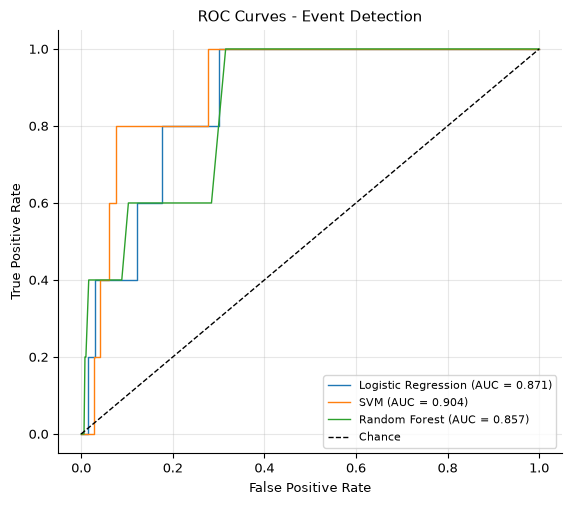


=== Discussion ===
Logistic Regression:
  - AUC: 0.8709, F1: 0.0420, recall: 1.0000, precision: 0.0215
SVM:
  - AUC: 0.9035, F1: 0.1455, recall: 0.8000, precision: 0.0800
Random Forest:
  - AUC: 0.8567, F1: 0.0000, recall: 0.0000, precision: 0.0000

Evenements : 5 sur 490 fenetres de test (1.0%) : les classes sont tres desequilibrees,
l'accuracy seule est donc trompeuse (un modele qui ne predit jamais d'evenement
aurait deja 99.0% d'accuracy) ; on juge sur F1 et AUC.


In [22]:
# Evaluate each model
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, roc_auc_score, roc_curve)

modeles_clf = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'SVM': SVC(kernel='rbf', probability=True, class_weight='balanced',
                                            random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced',
                                            random_state=42),
}

results = {}
probas = {}
modeles_fit = {}          # on garde les modeles ajustes : les cellules suivantes en ont besoin
for nom, modele in modeles_clf.items():
    modele.fit(X_train_scaled, y_train)
    modeles_fit[nom] = modele
    y_pred = modele.predict(X_test_scaled)
    y_prob = modele.predict_proba(X_test_scaled)[:, 1]
    probas[nom] = y_prob
    results[nom] = {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred, zero_division=0),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'auc': roc_auc_score(y_test, y_prob),
        'confusion': confusion_matrix(y_test, y_pred),
    }

# Print results
print('\n=== Classification Results ===')
for nom, res in results.items():
    print(f'\n{nom}:')
    print(f'  Accuracy:  {res["accuracy"]:.4f}')
    print(f'  Precision: {res["precision"]:.4f}')
    print(f'  Recall:    {res["recall"]:.4f}')
    print(f'  F1-score:  {res["f1"]:.4f}')
    print(f'  AUC:       {res["auc"]:.4f}')
    print(f'  Confusion Matrix:\n{res["confusion"]}')

display(pd.DataFrame({nom: {m: v for m, v in res.items() if m != 'confusion'}
                      for nom, res in results.items()}).T.round(3))

# Plot ROC curves
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for nom, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, probas[nom])
    ax.plot(fpr, tpr, label=f'{nom} (AUC = {res["auc"]:.3f})')
ax.plot([0, 1], [0, 1], 'k--', label='Chance')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves - Event Detection')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
savefig(fig, '9_roc_curves.png')
plt.show()

# Discussion
print('\n=== Discussion ===')
for nom, res in results.items():
    print(f'{nom}:')
    print(f'  - AUC: {res["auc"]:.4f}, F1: {res["f1"]:.4f}, '
          f'recall: {res["recall"]:.4f}, precision: {res["precision"]:.4f}')
print()
print(f'Evenements : {int(y_test.sum())} sur {len(y_test)} fenetres de test '
      f'({y_test.mean():.1%}) : les classes sont tres desequilibrees,')
print("l'accuracy seule est donc trompeuse (un modele qui ne predit jamais d'evenement")
print(f"aurait deja {1 - y_test.mean():.1%} d'accuracy) ; on juge sur F1 et AUC.")


### 7.1 Point de fonctionnement et fiabilité de la mesure

La cellule précédente classe avec `predict()`, c'est-à-dire un seuil implicite à 0,5 sur la probabilité. Deux problèmes, traités ci-dessous.

**1. Un seuil de 0,5 n'a aucun sens ici.** Les événements font ~1 % des fenêtres. Un modèle équilibré par `class_weight='balanced'` doit être coupé bien plus haut, sinon il annonce un événement presque partout ; un modèle laissé tel quel comme la Random Forest n'en annonce aucun. Le **point de fonctionnement** (le seuil appliqué au score) se choisit sur la **validation** : le tester d'abord reviendrait à choisir la règle en regardant la réponse.

**2. Les probabilités de deux modèles ne sont pas comparables.** Pour `SVC(probability=True)`, la calibration de Platt place les 5 événements de test entre 0,03 et 0,23 : un seuil à 0,5 sur `predict_proba` ne détecte rien, alors que `predict()` — qui utilise `decision_function` — en détecte 4. Chaque modèle est donc jugé sur son **score** propre : `decision_function` pour le SVM et pour la régression logistique, probabilité pour la Random Forest.

La validation ne contient cependant que **4 événements** au lieu des 5 % attendus : la seconde cellule mesure ce que vaut réellement un choix fait sur cet échantillon.


In [23]:
# Point de fonctionnement choisi sur la VALIDATION
# -----------------------------------------------
# Chaque modele est juge sur son score propre : une probabilite n'est pas comparable d'un
# modele a l'autre (pour SVC(probability=True), predict() et un seuil a 0,5 sur predict_proba
# ne coincident pas : les evenements de test ont une proba de 0,03 a 0,23).
from sklearn.metrics import precision_recall_curve


def score(modele, X):
    """Score de decision du modele : decision_function s'il en a un, sinon la probabilite."""
    if hasattr(modele, 'decision_function'):
        return modele.decision_function(X)
    return modele.predict_proba(X)[:, 1]


def seuil_f1(s, yy):
    """Seuil sur s qui maximise le F1 (choisi sur la validation)."""
    prec, rec, thr = precision_recall_curve(yy, s)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[int(np.argmax(f1))])


def seuil_youden(s, yy):
    """Seuil sur s qui maximise tpr - fpr, c'est-a-dire l'ecart au hasard (Youden)."""
    fpr, tpr, thr = roc_curve(yy, s)
    return float(thr[int(np.argmax(tpr - fpr))])


def mesure(s, yy, t=None, pred=None):
    """Metriques sur yy pour le score s, soit au seuil t, soit pour une prediction deja faite."""
    pred = (s >= t).astype(int) if pred is None else np.asarray(pred)
    tn, fp, fn, tp = confusion_matrix(yy, pred, labels=[0, 1]).ravel()
    return {'AUC': roc_auc_score(yy, s),
            'F1': f1_score(yy, pred, zero_division=0),
            'precision': precision_score(yy, pred, zero_division=0),
            'rappel': recall_score(yy, pred, zero_division=0),
            'TP': int(tp), 'FP': int(fp), 'FN': int(fn)}


SCORES = {nom: {'validation': score(m, X_val_scaled), 'test': score(m, X_test_scaled)}
          for nom, m in modeles_fit.items()}
SCORE_UTILISE = {nom: ('decision_function' if hasattr(m, 'decision_function') else 'probabilite')
                 for nom, m in modeles_fit.items()}

lignes = []
for nom, modele in modeles_fit.items():
    sv, st = SCORES[nom]['validation'], SCORES[nom]['test']
    lignes.append({'modele': nom, 'score': SCORE_UTILISE[nom], 'regle': 'predict() du modele',
                   'seuil choisi sur la validation': np.nan,
                   **mesure(st, y_test, pred=modele.predict(X_test_scaled))})
    for etiquette, t in (('seuil F1 validation', seuil_f1(sv, y_val)),
                         ('seuil Youden validation', seuil_youden(sv, y_val))):
        lignes.append({'modele': nom, 'score': SCORE_UTILISE[nom], 'regle': etiquette,
                       'seuil choisi sur la validation': t, **mesure(st, y_test, t)})

comparaison = pd.DataFrame(lignes)
print('Metriques sur le TEST selon la regle de decision retenue :')
display(comparaison.round(3))
print('Rappel : le F1 porte sur 5 evenements, il ne peut prendre que quelques valeurs.')


Metriques sur le TEST selon la regle de decision retenue :


,modele,score,regle,seuil choisi sur la validation,AUC,F1,precision,rappel,TP,FP,FN
0,Logistic Regression,decision_function,predict() du modele,NaN,0.871,0.042,0.021,1,5,228,0
1,Logistic Regression,decision_function,seuil F1 validation,5.277,0.871,0.089,0.05,0.4,2,38,3
2,Logistic Regression,decision_function,seuil Youden validation,2.567,0.871,0.072,0.038,0.8,4,102,1
3,SVM,decision_function,predict() du modele,NaN,0.904,0.145,0.08,0.8,4,46,1
4,SVM,decision_function,seuil F1 validation,2.7,0.904,0,0,0,0,0,5
5,SVM,decision_function,seuil Youden validation,-0.655,0.904,0.08,0.042,0.8,4,91,1
6,Random Forest,probabilite,predict() du modele,NaN,0.857,0,0,0,0,0,5
7,Random Forest,probabilite,seuil F1 validation,0.5,0.857,0,0,0,0,0,5
8,Random Forest,probabilite,seuil Youden validation,0.2,0.857,0.093,0.053,0.4,2,36,3


Rappel : le F1 porte sur 5 evenements, il ne peut prendre que quelques valeurs.


In [24]:
# Fiabilite de la mesure : combien d'evenements, et quelle incertitude
# --------------------------------------------------------------------
print('Evenements disponibles')
for nom_periode, yy in (('entrainement', y_train), ('validation', y_val), ('test', y_test)):
    print(f'  {nom_periode:<13} {len(yy):>4} fenetres   {int(yy.sum()):>3} evenements '
          f'({yy.mean():5.2%})')
print()
print(f'P95 du flux : entrainement {tab_train.flux.quantile(0.95):,.0f} | '
      f'validation {tab_val.flux.quantile(0.95):,.0f} | test {tab_test.flux.quantile(0.95):,.0f}')
print(f'  -> le seuil de {SEUIL_P95:,.0f} appris sur l entrainement ne capture plus')
print(f'     que {y_test.mean():.1%} des fenetres de test : le flux de 2024 est plus bas.')

RNG = np.random.default_rng(0)
N_TIRAGES = 2000


def ic_bootstrap(s, yy, t, n=N_TIRAGES):
    """IC 95 % de l AUC et du F1 par reechantillonnage des fenetres (avec remise)."""
    y, s = np.asarray(yy), np.asarray(s)
    aucs, f1s = [], []
    for _ in range(n):
        idx = RNG.integers(0, len(y), len(y))
        yb = y[idx]
        if yb.sum() in (0, len(yb)):        # tirage sans positif ou sans negatif
            continue
        aucs.append(roc_auc_score(yb, s[idx]))
        f1s.append(f1_score(yb, (s[idx] >= t).astype(int), zero_division=0))
    return np.array(aucs), np.array(f1s)


def ic(a):
    lo, hi = np.percentile(a, [2.5, 97.5])
    return f'[{lo:.2f} ; {hi:.2f}]'


lignes = []
for nom in modeles_fit:
    sv, st = SCORES[nom]['validation'], SCORES[nom]['test']
    t = seuil_f1(sv, y_val)
    a_val, f_val = ic_bootstrap(sv, y_val, t)
    a_test, f_test = ic_bootstrap(st, y_test, t)
    lignes.append({'modele': nom,
                   'AUC validation': roc_auc_score(y_val, sv), 'IC AUC validation': ic(a_val),
                   'F1 validation': f1_score(y_val, (sv >= t).astype(int), zero_division=0),
                   'IC F1 validation': ic(f_val),
                   'AUC test': roc_auc_score(y_test, st), 'IC AUC test': ic(a_test),
                   'F1 test (seuil val)': f1_score(y_test, (st >= t).astype(int), zero_division=0),
                   'IC F1 test': ic(f_test)})
print()
display(pd.DataFrame(lignes).set_index('modele'))

noms = list(modeles_fit)
print()
print('La validation departage-t-elle les modeles ? (part des tirages ou le premier a la')
print('meilleure AUC de validation) :')
for a in range(len(noms)):
    for b in range(a + 1, len(noms)):
        gagne = tot = 0
        for _ in range(1000):
            idx = RNG.integers(0, len(y_val), len(y_val))
            yb = np.asarray(y_val)[idx]
            if yb.sum() in (0, len(yb)):
                continue
            tot += 1
            gagne += roc_auc_score(yb, SCORES[noms[a]]['validation'][idx]) > \
                roc_auc_score(yb, SCORES[noms[b]]['validation'][idx])
        print(f'  {noms[a]:<20} > {noms[b]:<20} {gagne / tot:5.1%}  ({tot} tirages valides)')

print()
print('Position des evenements de test dans le classement de chaque modele :')
for nom in noms:
    st = np.asarray(SCORES[nom]['test'])
    rangs = np.sort(pd.Series(st).rank(ascending=False).values[np.asarray(y_test) == 1])
    print(f'  {nom:<20} ' + ', '.join(f'rang {int(r):>3} / {len(st)}' for r in rangs))


Evenements disponibles
  entrainement  2364 fenetres   123 evenements (5.20%)
  validation     509 fenetres     4 evenements (0.79%)
  test           490 fenetres     5 evenements (1.02%)

P95 du flux : entrainement 18,727 | validation 12,910 | test 12,394
  -> le seuil de 18,727 appris sur l entrainement ne capture plus
     que 1.0% des fenetres de test : le flux de 2024 est plus bas.


,AUC validation,IC AUC validation,F1 validation,IC F1 validation,AUC test,IC AUC test,F1 test (seuil val),IC F1 test
modele,,,,,,,,
Logistic Regression,0.6881,[0.39 ; 0.96],0.1,[0.00 ; 0.29],0.8709,[0.75 ; 0.98],0.08889,[0.00 ; 0.22]
SVM,0.7861,[0.63 ; 1.00],0.3333,[0.00 ; 0.80],0.9035,[0.79 ; 0.97],0,[0.00 ; 0.00]
Random Forest,0.797,[0.54 ; 0.96],0.09091,[0.00 ; 0.28],0.8567,[0.71 ; 0.99],0,[0.00 ; 0.00]



La validation departage-t-elle les modeles ? (part des tirages ou le premier a la
meilleure AUC de validation) :


  Logistic Regression  > SVM                  14.4%  (988 tirages valides)


  Logistic Regression  > Random Forest         9.2%  (992 tirages valides)


  SVM                  > Random Forest        41.8%  (989 tirages valides)

Position des evenements de test dans le classement de chaque modele :
  Logistic Regression  rang   8 / 490, rang  17 / 490, rang  62 / 490, rang  90 / 490, rang 151 / 490
  SVM                  rang  15 / 490, rang  22 / 490, rang  32 / 490, rang  41 / 490, rang 139 / 490
  Random Forest        rang   4 / 490, rang   8 / 490, rang  49 / 490, rang 150 / 490, rang 150 / 490


**Lecture.** Le point de fonctionnement se choisit sur la validation — mais ici la validation ne peut pas le choisir, et la cellule précédente le montre :

* **Le réglage du seuil dégrade le meilleur modèle.** Le SVM passe de F1 = 0,145 avec `predict()` à 0,000 avec le seuil qui maximise le F1 de validation. Seule la Random Forest y gagne vraiment (F1 = 0,000 → 0,093) : son seuil implicite de 0,5 est simplement inadapté à 1 % de positifs. Un seuil réglé achète au mieux 2 à 4 événements trouvés, au prix de 36 à 102 fausses alertes — inutilisable comme alarme.
* **La validation ne départage pas les modèles** : 4 événements seulement, des IC d'AUC de validation qui se recouvrent presque entièrement, et le classement qui s'inverse dans ~40 % des rééchantillonnages. Choisir un modèle sur ce critère revient à tirer à pile ou face.
* **Le seuil d'événement dérive** : le p95 appris sur 2020-2023 vaut 18 727 mais le p95 du flux de 2024 est proche de 12 400, si bien que l'année de test ne contient plus que 5 événements (1,0 %) au lieu de 5 %. Ce n'est pas un défaut de méthode : c'est le flux de la région qui est plus bas en 2024.
* **Ce qui reste solide** : l'information est réelle — AUC de test 0,86 à 0,90 contre 0,5 au hasard — mais faible et concentrée : les 5 événements se placent dans le top 2 % du classement pour deux d'entre eux, vers le 30ᵉ percentile pour les deux autres.

**Conséquence pour le rapport :** avec 4 et 5 événements, ni le seuil ni le modèle ne peuvent être choisis de façon fiable, et un F1 calculé sur 5 positifs n'a pas d'intervalle de confiance exploitable (bootstrap dégénéré). C'est la taille de l'échantillon d'événements qu'il faut d'abord corriger — élargir la période de test (2023-2024) et/ou une validation croisée glissante — avant d'accorder du crédit à une comparaison de modèles. En attendant, la seule quantité à rapporter est l'AUC (éventuellement complétée par l'AP et la courbe précision-rappel), pas le F1.


**Lecture :** seuil P95 = **≈ 17 000 #/cm²/s/sr** (log10 ≈ 4,23), soit **178 fenêtres de 12 h regroupées en
74 épisodes**. Les épisodes les plus intenses durent plusieurs jours (septembre 2022, avril–mai 2023 : jusqu'à
10 jours au-dessus du seuil). Seulement 8 épisodes en 2024 (année de test du Step 2) : les événements y seront
rares, d'où l'importance de métriques adaptées aux classes déséquilibrées (F1, AUC) au Step 2.

# Step 2 : modélisation par apprentissage automatique

## 8. Régression : prédire le flux à +12, +24, +36 et +48 h (énoncé 4.1)

### 8.1 Données d'entrée et découpage entraînement / test
On part de la **table 12 h** produite au point 4 (`data/table_12h.parquet`).

**Ce que le modèle reçoit (les entrées X) :** à un instant t, on ne connaît que le passé. On donne donc au modèle
le log10 du flux et les paramètres solaires **à t, t − 12 h et t − 24 h** (le flux réagit au vent solaire avec 1 à
2 jours de retard, les valeurs passées sont donc utiles).

**Ce qu'il doit prédire (les cibles Y) :** le log10 du flux **12, 24, 36 et 48 h plus tard**. On prédit le log10
et pas le flux lui-même, car le flux varie sur plusieurs ordres de grandeur : sans log, les quelques valeurs
d'orage écraseraient tout le reste.

**Découpage honnête (l'énoncé insiste) :** le test doit jouer le rôle d'un **futur que le modèle n'a jamais vu**.
On coupe donc **dans le temps**, et pas au hasard :
* **entraînement : 2020 → 2023** (le modèle apprend) ;
* **test : 2024** (on mesure ses performances), qui contient en plus le gros orage de mai 2024.

Un découpage au hasard tricherait : deux fenêtres de 12 h voisines se ressemblent beaucoup, le modèle aurait vu
« la veille » de presque chaque date de test. On retire aussi les 2 derniers jours de 2023 de l'entraînement :
leurs cibles à +48 h tombent déjà en 2024.

33 entrées : 11 paramètres x 3 instants (t, t-12 h, t-24 h)
Entraînement : 2662 fenêtres (2020-01-02 -> 2023-12-29)
Test         : 598 fenêtres (2024-01-01 -> 2024-12-29)
Fenêtres écartées (valeur manquante ou cible à cheval sur 2024) : 394


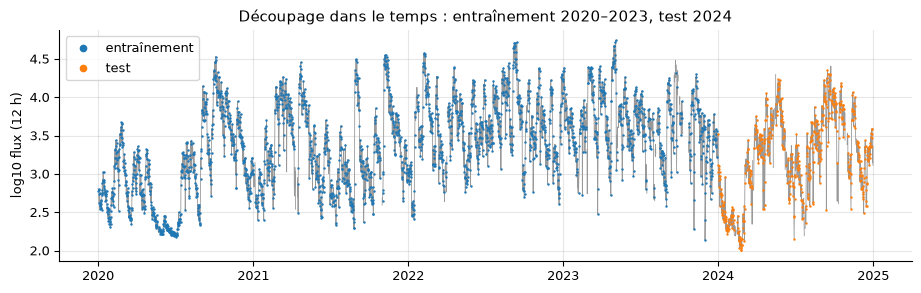

In [25]:
tab = pd.read_parquet(os.path.join(DATA, 'table_12h.parquet'))

PARAMS = ['log_flux', 'V_kms', 'Bz_nT', 'F107_sfu', 'N_cm3', 'P_nPa', 'E_mVm', 'B_nT', 'Kp', 'Dst_nT', 'AE_nT']
HORIZONS = [1, 2, 3, 4]                 # en pas de 12 h : +12, +24, +36, +48 h
TEST_START = pd.Timestamp('2024-01-01')

# Entrées X(t) : chaque paramètre à t, t-12 h et t-24 h (shift(k) = valeur k pas de 12 h plus tôt)
X = pd.DataFrame({f'{c}_t-{12 * k}h': tab[c].shift(k) for c in PARAMS for k in (0, 1, 2)})
# Cibles Y(t) : log10 du flux 12, 24, 36, 48 h plus tard (shift(-h) = valeur h pas plus tard)
Y = pd.DataFrame({f'+{12 * h}h': tab['log_flux'].shift(-h) for h in HORIZONS})

# On ne garde que les instants où toutes les entrées et toutes les cibles existent
ok = X.notna().all(axis=1) & Y.notna().all(axis=1)
train = ok & (X.index < TEST_START - pd.Timedelta(hours=12 * max(HORIZONS)))   # cibles avant 2024
test = ok & (X.index >= TEST_START)
X_train, Y_train = X[train], Y[train]
X_test, Y_test = X[test], Y[test]

print(f'{X.shape[1]} entrées : {len(PARAMS)} paramètres x 3 instants (t, t-12 h, t-24 h)')
print(f'Entraînement : {len(X_train)} fenêtres ({X_train.index.min():%Y-%m-%d} -> {X_train.index.max():%Y-%m-%d})')
print(f'Test         : {len(X_test)} fenêtres ({X_test.index.min():%Y-%m-%d} -> {X_test.index.max():%Y-%m-%d})')
print(f'Fenêtres écartées (valeur manquante ou cible à cheval sur 2024) : {(~(train | test)).sum()}')

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(tab.index, tab['log_flux'], color='0.6', lw=0.6)
ax.plot(X_train.index, tab.loc[X_train.index, 'log_flux'], '.', ms=1.5, color='C0', label='entraînement')
ax.plot(X_test.index, tab.loc[X_test.index, 'log_flux'], '.', ms=1.5, color='C1', label='test')
ax.set_ylabel('log10 flux (12 h)')
ax.set_title(f'Découpage dans le temps : entraînement 2020–2023, test 2024')
ax.legend(markerscale=6)
savefig(fig, '8_decoupage.png')
plt.show()

### 8.2 Baseline (persistance) et régression linéaire

**La baseline** est le modèle le plus bête possible, qui sert de point de comparaison (l'énoncé l'exige) : la
**persistance**, « le flux dans 12, 24, 36 ou 48 h sera le même que maintenant ». Elle est difficile à battre à
court terme, car le flux change lentement. Un modèle n'a d'intérêt que s'il fait **mieux** qu'elle.

**La régression linéaire** cherche la meilleure combinaison linéaire des 33 entrées :
log10 flux(t + h) ≈ a₀ + a₁·entrée₁ + a₂·entrée₂ + … Un modèle séparé est entraîné pour chaque horizon h.
Les entrées sont d'abord **standardisées** (moyenne 0, écart-type 1, calculés sur l'entraînement seulement) pour
que les coefficients soient comparables entre eux.

**Les métriques** (calculées sur le test 2024, en unités de log10 flux) :
* **RMSE** (racine de l'erreur quadratique moyenne) : erreur typique, pénalise fort les grosses erreurs.
  RMSE = 0,3 signifie une erreur typique d'un facteur 10^0,3 ≈ 2 sur le flux ;
* **MAE** (erreur absolue moyenne) : erreur moyenne, moins sensible aux grosses erreurs ;
* **R²** : part de la variabilité du flux expliquée par le modèle (1 = parfait, 0 = pas mieux que prédire la
  moyenne, négatif = pire que la moyenne).

Persistance             Régression linéaire            
            RMSE   MAE    R²                RMSE   MAE    R²
+12h       0.219 0.175 0.844                0.17 0.123 0.906
+24h       0.236  0.16 0.819               0.195 0.142 0.876
+36h       0.319 0.238  0.67                0.24 0.179 0.813
+48h       0.319 0.221  0.67               0.248 0.187 0.801

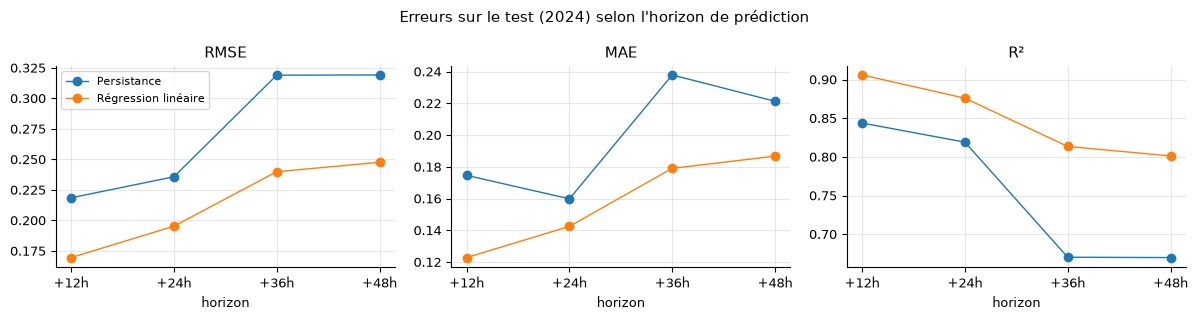

In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def scores(y_vrai, y_pred):
    """RMSE, MAE et R² (en unités de log10 flux)."""
    return {'RMSE': np.sqrt(mean_squared_error(y_vrai, y_pred)),
            'MAE': mean_absolute_error(y_vrai, y_pred),
            'R²': r2_score(y_vrai, y_pred)}

predictions = {}   # predictions[modèle] = DataFrame des prédictions sur le test (une colonne par horizon)
resultats = {}     # resultats[modèle] = DataFrame des métriques (une ligne par horizon)

# Baseline : persistance (flux futur = flux actuel)
predictions['Persistance'] = pd.DataFrame({h: X_test['log_flux_t-0h'] for h in Y.columns})

# Régression linéaire : un modèle par horizon (standardisation apprise sur l'entraînement seulement)
predictions['Régression linéaire'] = pd.DataFrame(index=X_test.index)
modeles_lin = {}
for h in Y.columns:
    modele = make_pipeline(StandardScaler(), LinearRegression())
    modele.fit(X_train, Y_train[h])
    modeles_lin[h] = modele
    predictions['Régression linéaire'][h] = modele.predict(X_test)

for nom, pred in predictions.items():
    resultats[nom] = pd.DataFrame({h: scores(Y_test[h], pred[h]) for h in Y.columns}).T

display(pd.concat(resultats, axis=1).round(3))

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for nom, res in resultats.items():
    for a, m in zip(ax, ['RMSE', 'MAE', 'R²']):
        a.plot(res.index, res[m], 'o-', label=nom)
        a.set_title(m)
        a.set_xlabel('horizon')
ax[0].legend(fontsize=8)
fig.suptitle('Erreurs sur le test (2024) selon l\'horizon de prédiction')
fig.tight_layout()
savefig(fig, '8_metriques_lineaire.png')
plt.show()

**Lecture :**
* la **régression linéaire bat la persistance à tous les horizons** : RMSE 0,17 → 0,25 contre 0,22 → 0,32, et
  R² 0,91 → 0,80 contre 0,84 → 0,67. Le gain grandit avec l'horizon (à +48 h, l'erreur baisse de ~22 %) : plus on
  prédit loin, plus le vent solaire des jours précédents apporte d'information que le flux actuel n'a pas ;
* l'erreur augmente avec l'horizon, comme attendu : RMSE = 0,25 à +48 h correspond à une erreur typique d'un
  facteur 10^0,25 ≈ 1,8 sur le flux ;
* **curiosité : la persistance est moins bonne à +12 h qu'à +24 h** (MAE 0,175 contre 0,160). Le flux de la
  fenêtre 12h–24h UTC est **systématiquement plus bas** que celui de la fenêtre 00h–12h (de 0,14 en log10, soit un
  facteur 1,4, dans 84 % des cas). NOAA-15 a une orbite héliosynchrone : il passe toujours à la même heure locale,
  donc selon l'heure UTC il survole des **longitudes différentes**. Or le champ magnétique terrestre n'est pas
  symétrique (anomalie de l'Atlantique Sud) : à même L, le flux mesuré à 810 km dépend de la longitude. « Même
  fenêtre hier » (+24 h) ressemble donc plus à aujourd'hui que « la fenêtre suivante » (+12 h). La régression
  linéaire compense en partie grâce aux valeurs passées (t − 12 h, t − 24 h).

### 8.3 Random Forest
Une **forêt aléatoire** (Random Forest) est un ensemble de **arbres de décision**. Chaque arbre pose une suite de
questions simples sur les entrées (« V il y a 24 h > 500 km/s ? », « flux actuel > 10³ ? »…) et arrive à une
prédiction. Chaque arbre est entraîné sur un tirage au hasard des données ; la forêt fait la **moyenne** de tous
les arbres, ce qui rend la prédiction plus stable qu'un arbre seul.

Différence avec la régression linéaire : la forêt peut capter des relations **non linéaires** et des
**combinaisons** d'entrées (par exemple : un vent rapide n'accélère les électrons que si Bz est négatif).

Réglages (fixés à l'avance, sans regarder le test) : 300 arbres ; au moins 5 fenêtres par feuille, pour éviter que
les arbres apprennent par cœur les données d'entraînement ; à chaque question, un tiers des entrées tirées au
hasard. Un modèle par horizon, comme pour la régression linéaire.

L'**importance des entrées** mesure combien chaque entrée a servi à réduire l'erreur dans les arbres : elle dit
sur quoi le modèle s'appuie.

Persistance             Régression linéaire             Random Forest            
            RMSE   MAE    R²                RMSE   MAE    R²          RMSE   MAE    R²
+12h       0.219 0.175 0.844                0.17 0.123 0.906         0.176 0.136 0.899
+24h       0.236  0.16 0.819               0.195 0.142 0.876         0.215 0.162 0.849
+36h       0.319 0.238  0.67                0.24 0.179 0.813         0.268  0.21 0.767
+48h       0.319 0.221  0.67               0.248 0.187 0.801         0.297 0.232 0.715

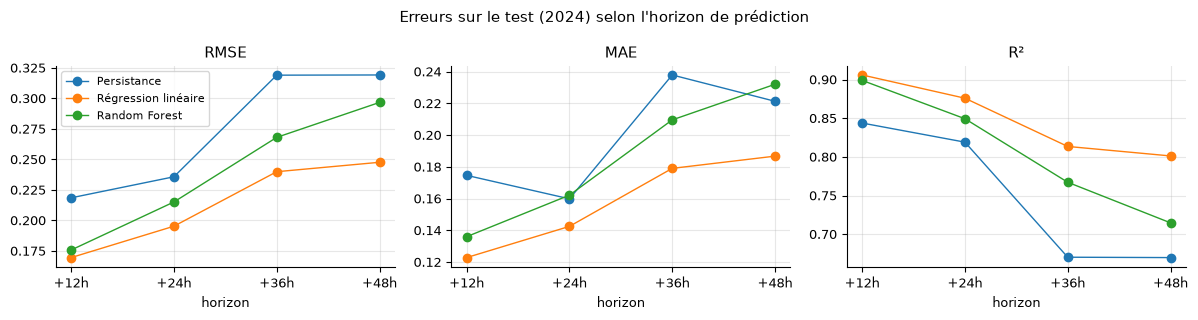

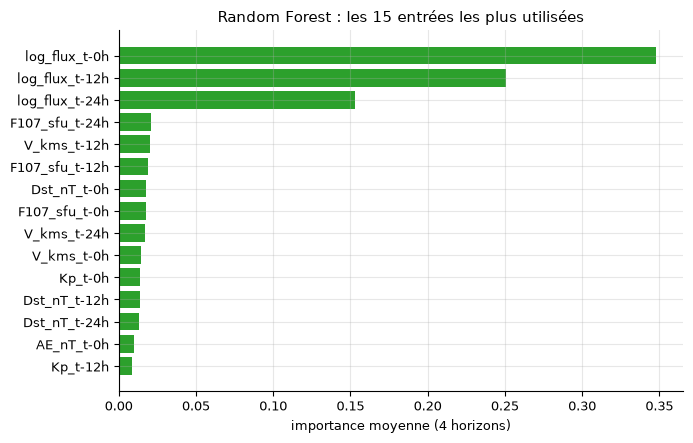

,+12h,+24h,+36h,+48h
log_flux_t-0h,0.365,0.407,0.28,0.34
log_flux_t-12h,0.326,0.201,0.307,0.168
log_flux_t-24h,0.143,0.177,0.124,0.168
F107_sfu_t-24h,0.018,0.02,0.022,0.024
V_kms_t-12h,0.01,0.016,0.026,0.028
F107_sfu_t-12h,0.018,0.016,0.019,0.023
Dst_nT_t-0h,0.007,0.013,0.022,0.029
F107_sfu_t-0h,0.017,0.018,0.018,0.016
V_kms_t-24h,0.012,0.018,0.021,0.019
V_kms_t-0h,0.003,0.008,0.018,0.028


In [27]:
from sklearn.ensemble import RandomForestRegressor

predictions['Random Forest'] = pd.DataFrame(index=X_test.index)
modeles_rf = {}
for h in Y.columns:
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=1 / 3,
                               random_state=0, n_jobs=-1)
    rf.fit(X_train, Y_train[h])
    modeles_rf[h] = rf
    predictions['Random Forest'][h] = rf.predict(X_test)
resultats['Random Forest'] = pd.DataFrame({h: scores(Y_test[h], predictions['Random Forest'][h])
                                           for h in Y.columns}).T

display(pd.concat(resultats, axis=1).round(3))

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for nom, res in resultats.items():
    for a, m in zip(ax, ['RMSE', 'MAE', 'R²']):
        a.plot(res.index, res[m], 'o-', label=nom)
        a.set_title(m)
        a.set_xlabel('horizon')
ax[0].legend(fontsize=8)
fig.suptitle('Erreurs sur le test (2024) selon l\'horizon de prédiction')
fig.tight_layout()
savefig(fig, '8_metriques_3_modeles.png')
plt.show()

# Importance des entrées (moyenne sur les 4 horizons), les 15 plus utiles
importance = pd.DataFrame({h: modeles_rf[h].feature_importances_ for h in Y.columns}, index=X.columns)
top = importance.mean(axis=1).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index, top.values, color='C2')
ax.set_xlabel('importance moyenne (4 horizons)')
ax.set_title('Random Forest : les 15 entrées les plus utilisées')
fig.tight_layout()
savefig(fig, '8_importance_rf.png')
plt.show()
display(importance.loc[top.index[::-1]].round(3))

**Lecture :**
* la Random Forest **bat la persistance**, mais **fait moins bien que la régression linéaire**, et l'écart grandit
  avec l'horizon (RMSE à +48 h : 0,30 contre 0,25 ; R² : 0,71 contre 0,80). Un modèle plus complexe n'est donc pas
  forcément meilleur : c'est un résultat à discuter dans le rapport ;
* **ce qu'elle utilise** : surtout le flux actuel et passé (t, t − 12 h, t − 24 h), qui pèse ~80 % de l'importance.
  Viennent ensuite F10.7, V, Dst et Kp, dont le poids **augmente avec l'horizon** : à +48 h, le flux actuel en dit
  moins, le vent solaire et l'activité géomagnétique en disent plus (comme vu aux corrélations retardées, point 6.3).

**Pourquoi la forêt souffre sur 2024 : le test ne ressemble pas tout à fait à l'entraînement.**
* **Une forêt ne sait pas extrapoler** : sa prédiction est une moyenne de valeurs vues à l'entraînement, elle ne
  peut jamais sortir de cette plage. Or début 2024, le flux descend plus bas que tout ce qui existe en 2020–2023
  (log10 = 2,00 contre 2,14 au minimum). La régression linéaire, elle, prolonge la tendance ;
* **F10.7 sert de « calendrier » à la forêt** : 2024 est au maximum du cycle solaire, F10.7 y vaut **192 en
  moyenne contre 110 sur 2020–2023**. Des valeurs aussi hautes, la forêt ne les a vues qu'en 2023 : elle prédit donc
  2024 « comme 2023 ». F10.7 varie lentement avec le cycle solaire, il ne dit presque rien sur les variations à 12–48 h.

Pistes d'amélioration (à tester sans utiliser le test, par exemple sur une période de validation 2023) : retirer
F10.7 des entrées, ou prédire la **variation** du flux (flux(t + h) − flux(t)) plutôt que sa valeur.